In [1]:
pip install pandas

In [2]:
# Import required Libraries

import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [3]:
# Load the CSV file

df = pd.read_csv('../SyntheticData_Training.csv')
df.head()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,1,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,2,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,3,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,4,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,5,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0


In [4]:
df = df.loc[:, ~df.columns.str.startswith('admitabx_adm')]
df = df.drop(columns=['lengthadm'])

In [5]:
# Dataframe shape
df.shape

(2686, 118)

In [6]:
# retrieving columns Label
df.columns


Index(['studyid_adm', 'agecalc_adm', 'height_cm_adm', 'weight_kg_adm',
       'muac_mm_adm', 'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm',
       'diasbp_mmhg_adm', 'temp_c_adm',
       ...
       'cookfuel_adm___8', 'cookloc_adm', 'lightfuel_adm', 'tobacco_adm',
       'bednet_adm', 'hctpretransfusion_adm', 'hivstatus_adm',
       'malariastatuspos_adm', 'caregiver_adm_new', 'inhospital_mortality'],
      dtype='object', length=118)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 118 entries, studyid_adm to inhospital_mortality
dtypes: float64(23), int64(2), object(93)
memory usage: 2.4+ MB


In [8]:
# Check for null values
df.isnull().sum()

studyid_adm               0
agecalc_adm               0
height_cm_adm            14
weight_kg_adm             9
muac_mm_adm              13
                         ..
hctpretransfusion_adm    43
hivstatus_adm             5
malariastatuspos_adm      2
caregiver_adm_new         3
inhospital_mortality      0
Length: 118, dtype: int64

In [9]:
# Check for null values
null_counts = df.isnull().sum()

# Filter and print columns with non-zero null value counts
columns_with_null = null_counts[null_counts > 0].index
print(df[columns_with_null])

      height_cm_adm  weight_kg_adm  muac_mm_adm  hr_bpm_adm  rr_brpm_app_adm   
0              79.8           11.6        150.0       130.0             23.0  \
1              93.0           13.6        151.0       115.0             35.0   
2              68.2            8.2        148.0       150.0             56.0   
3              95.0           12.0        138.0       134.0             38.0   
4              83.0           12.0        165.0       163.0             61.0   
...             ...            ...          ...         ...              ...   
2681           98.2           10.0        135.0       163.0             61.0   
2682           82.3           10.0        140.0       115.0             37.0   
2683           82.4           12.7        145.0       150.0             40.0   
2684           67.5            7.5        130.0       145.0             26.0   
2685           77.8            8.0        131.0       146.0             38.0   

      sysbp_mmhg_adm  diasbp_mmhg_adm  

In [10]:
df.describe()


,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,householdsize_adm,alivechildren_adm,deadchildren_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,inhospital_mortality
count,2686.000000,2686.00000,2672.000000,2677.000000,2673.000000,2685.000000,2681.000000,2684.000000,2685.000000,2685.000000,...,2683.000000,2682.00000,2685.000000,2229.000000,2222.000000,469.000000,2677.000000,2556.000000,2479.000000,2686.000000
mean,1343.500000,21.12338,79.659401,9.577265,138.076693,141.219367,46.179784,96.941133,54.594041,37.470503,...,5.142751,3.02349,0.354935,32.954240,2.774887,2.951599,6.320882,88.780516,78.004841,0.044304
std,775.525736,13.05725,11.110075,2.796121,15.934621,25.550612,14.871732,11.876974,11.005274,1.007606,...,2.132131,1.81805,0.810868,9.750002,2.123403,2.234946,2.512912,16.714758,23.383975,0.205808
min,1.000000,5.90000,56.000000,2.610000,75.000000,42.000000,17.000000,58.000000,15.000000,33.600000,...,2.000000,0.00000,0.000000,6.000000,0.500000,0.200000,0.000000,0.000000,0.000000,0.000000
25%,672.250000,10.52500,71.500000,7.640000,130.000000,128.000000,35.000000,89.000000,48.000000,36.700000,...,4.000000,2.00000,0.000000,28.000000,1.500000,1.400000,5.000000,87.000000,68.000000,0.000000
50%,1343.500000,16.90000,78.000000,9.000000,140.000000,143.000000,44.000000,96.000000,54.000000,37.200000,...,5.000000,3.00000,0.000000,34.000000,2.100000,2.300000,6.000000,96.000000,87.000000,0.000000
75%,2014.750000,28.67500,86.700000,11.000000,149.000000,158.000000,56.000000,104.000000,62.000000,38.200000,...,6.000000,4.00000,0.000000,40.000000,3.300000,3.700000,7.200000,99.000000,96.000000,0.000000
max,2686.000000,61.80000,122.000000,22.000000,190.000000,214.000000,116.000000,159.000000,103.000000,40.600000,...,19.000000,11.00000,9.000000,82.000000,18.900000,15.900000,24.200000,99.000000,99.000000,1.000000


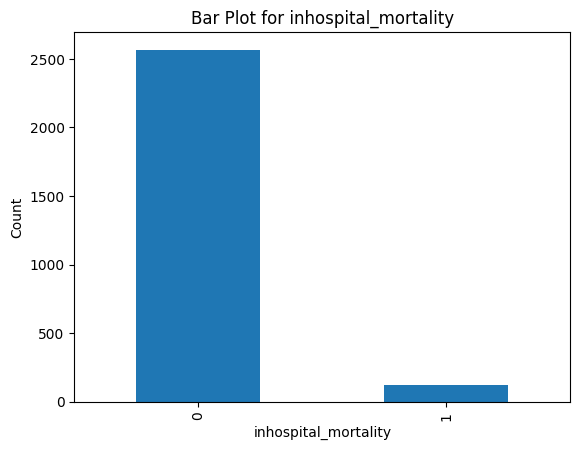

In [11]:
# Inhospital_mortality label balance
# Specify the column name
column_name = 'inhospital_mortality'  # Replace with the actual column name

# Create a bar plot of the specified column
df[column_name].value_counts().plot(kind='bar')

# Set plot title and labels
plt.title('Bar Plot for {}'.format(column_name))
plt.xlabel(column_name)
plt.ylabel('Count')

# Display the plot
plt.show()

In [12]:
column_name = 'inhospital_mortality'  #
total_count = len(df)  # Total count of rows in the DataFrame
mortality_count = df[column_name].value_counts().get(1, 0)  # Count of '1' values in the column

percentage = (mortality_count / total_count) * 100

print("Percentage of mortality values in {}: {:.2f}%".format(column_name, percentage))

Percentage of mortality values in inhospital_mortality: 4.43%


In [13]:
def plots(column_name):
  
    # Create a figure with subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Plot histogram for a column
    axes[0].hist(df[column_name])
    axes[0].set_title('Histogram of {}'.format(column_name))
    axes[0].set_xlabel(column_name)
    axes[0].set_ylabel('Frequency')

    # Create a boxplot based on attrition
    sns.boxplot(data=df, x='inhospital_mortality', y=column_name, ax=axes[1])
    axes[1].set_title('Boxplot of {} by inhospital_mortality'.format(column_name))
    axes[1].set_xlabel('inhospital_mortality')
    axes[1].set_ylabel(column_name)

    # Create a violin plot to visualize selected column distribution by attrition
    sns.violinplot(data=df, x='inhospital_mortality', y=column_name, ax=axes[2])
    axes[2].set_title('Distribution of {} by inhospital_mortality'.format(column_name))
    axes[2].set_xlabel('inhospital_mortality')
    axes[2].set_ylabel(column_name)

    # Adjust the spacing between subplots
    plt.tight_layout()

    # Show the plots
    plt.show()

In [14]:
# statistical significance functions
# testing normality
# H0:normal
# H1: not normal
def normality (column_name):
    stat, p = stats.shapiro(df[column_name])
    if p < 0.05:
        return " for '{}'distirbution is not normal".format(column_name)
    else:
        return "for '{}'distirbution is normal".format(column_name)
    
#testing mean equality a t-test for equal variance, the hypotheses are:
# H<sub>0</sub>: averages are equal
# H<sub>a</sub>: averages are not equal
def mean_equal (column_name):
    mortality_average = df[df['inhospital_mortality']==1][column_name]
    alive_average = df[df['inhospital_mortality']==0][column_name]
    stat, p = stats.ttest_ind( mortality_average, alive_average)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
    
 # average equality for non equal variance   
def equalmean_inequalvariance(column_name):
    alive= df[df['inhospital_mortality']==0][column_name]
    mortality = df[df['inhospital_mortality']==1][column_name]
    stat, p = stats.ttest_ind(alive, mortality, equal_var=False)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
 # average equality for equal variance
def mean_equal_all (column_name):
    alive= df[df['inhospital_mortality']==0][column_name]
    mortality = df[df['inhospital_mortality']==1][column_name]
    stat, p = stats.levene(alive,mortality)
    if p < 0.05:
        return "variance is not equal".format(column_name), equalmean_inequalvariance(column_name)
    else:
        return "variance is equal".format(column_name), mean_equal(column_name)


In [15]:
def plots_statistical_analysis(column_name):
    plots(column_name)
    return normality(column_name),mean_equal_all(column_name)

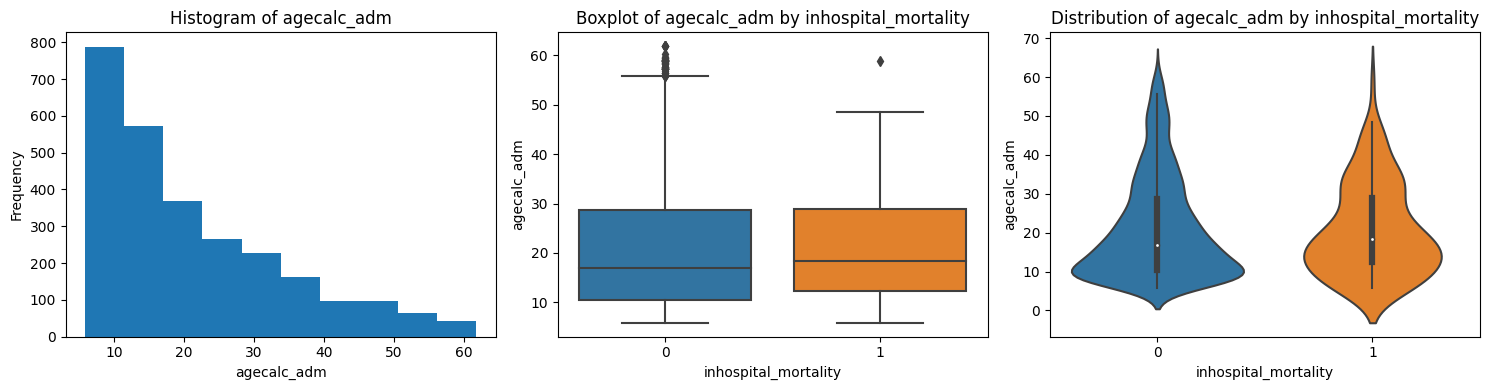

(" for 'agecalc_adm'distirbution is not normal",
 ('variance is equal', 'average are equal'))

In [16]:
plots_statistical_analysis('agecalc_adm')


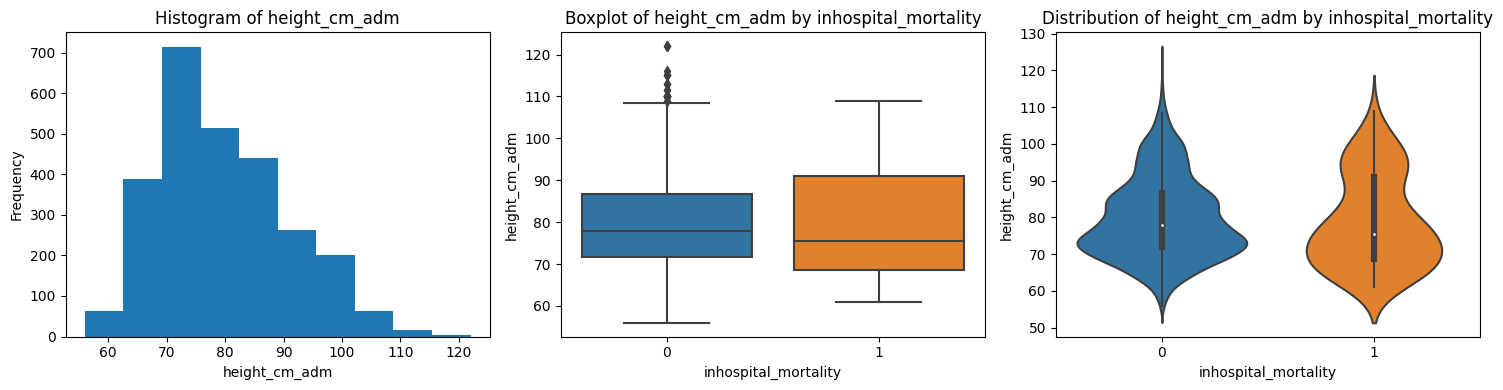

("for 'height_cm_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [17]:
plots_statistical_analysis('height_cm_adm')

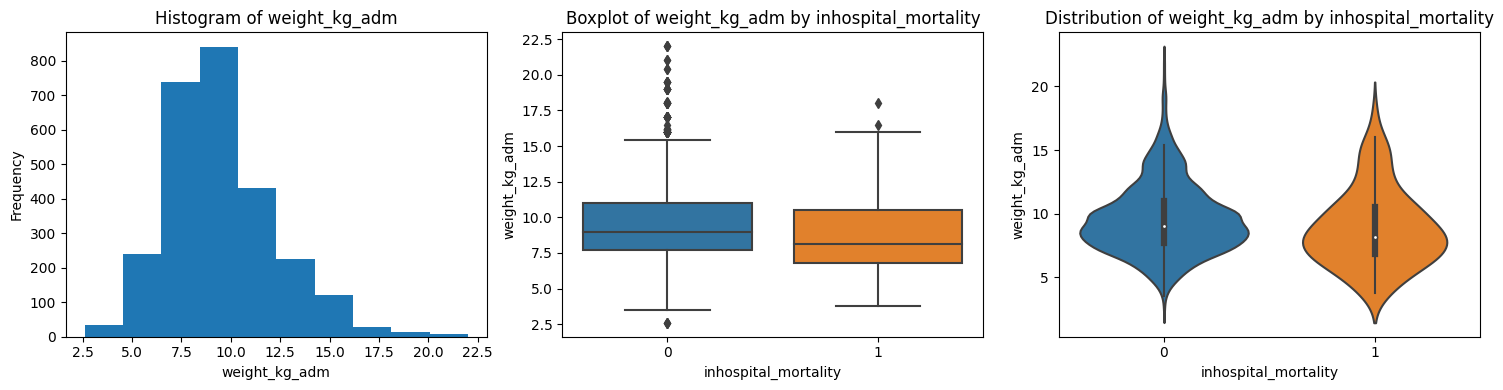

("for 'weight_kg_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [18]:
plots_statistical_analysis('weight_kg_adm')

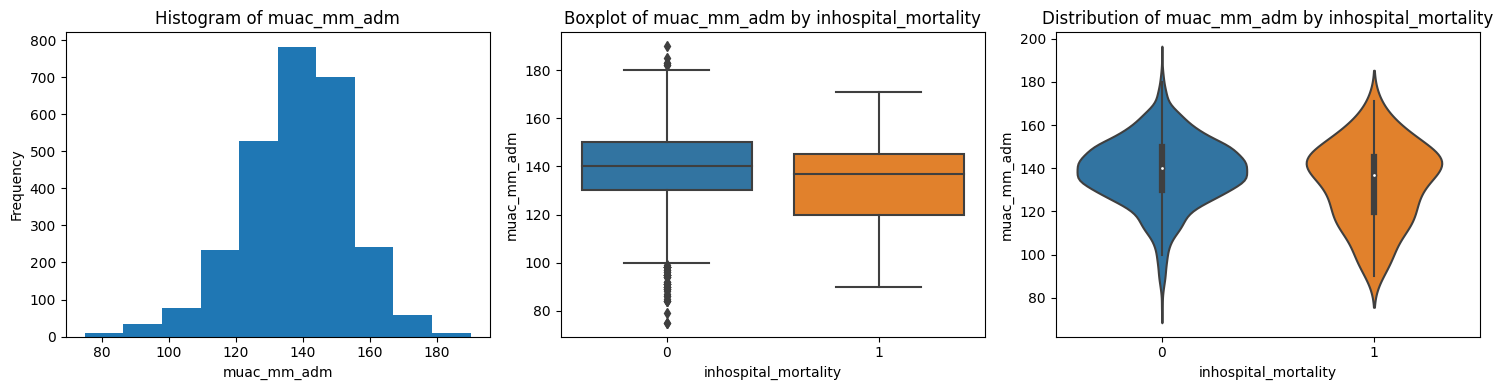

("for 'muac_mm_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [19]:
# Nutrition assessment <115 Severe Acute malnutrition 116-124 moderate >=125 normal
plots_statistical_analysis('muac_mm_adm')

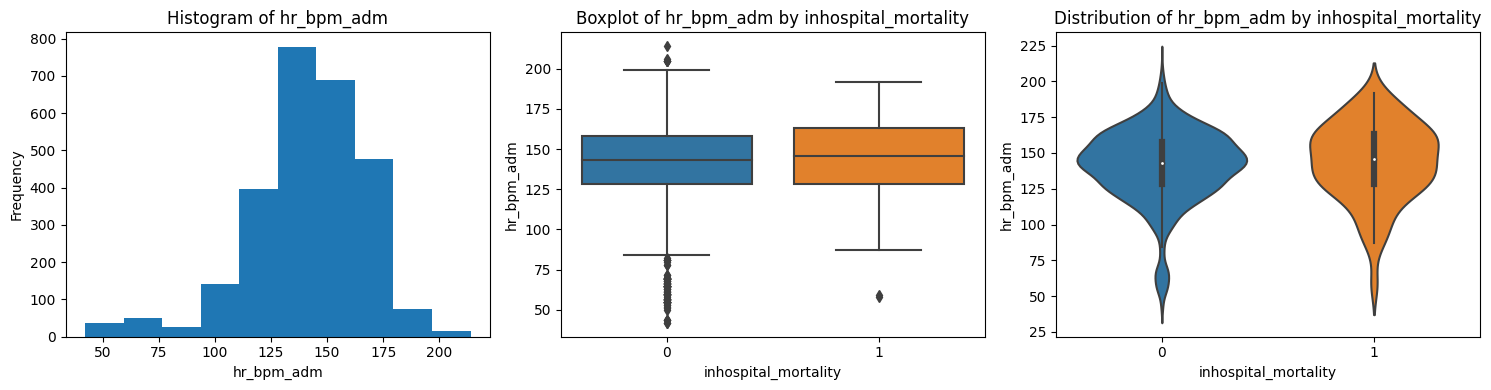

("for 'hr_bpm_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [20]:
# Heart Rate
plots_statistical_analysis('hr_bpm_adm')

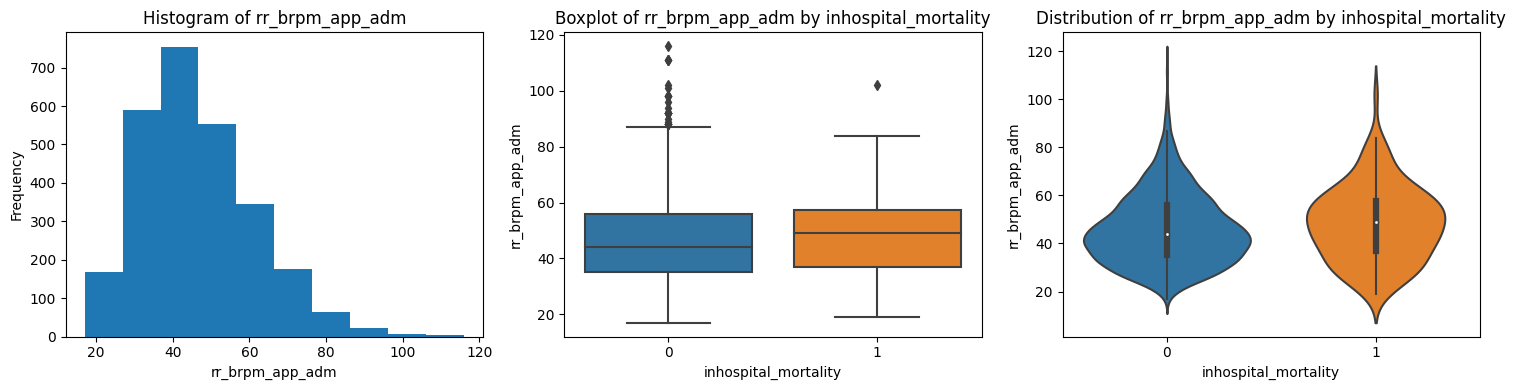

("for 'rr_brpm_app_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [21]:
# Respiratory rate
plots_statistical_analysis('rr_brpm_app_adm')

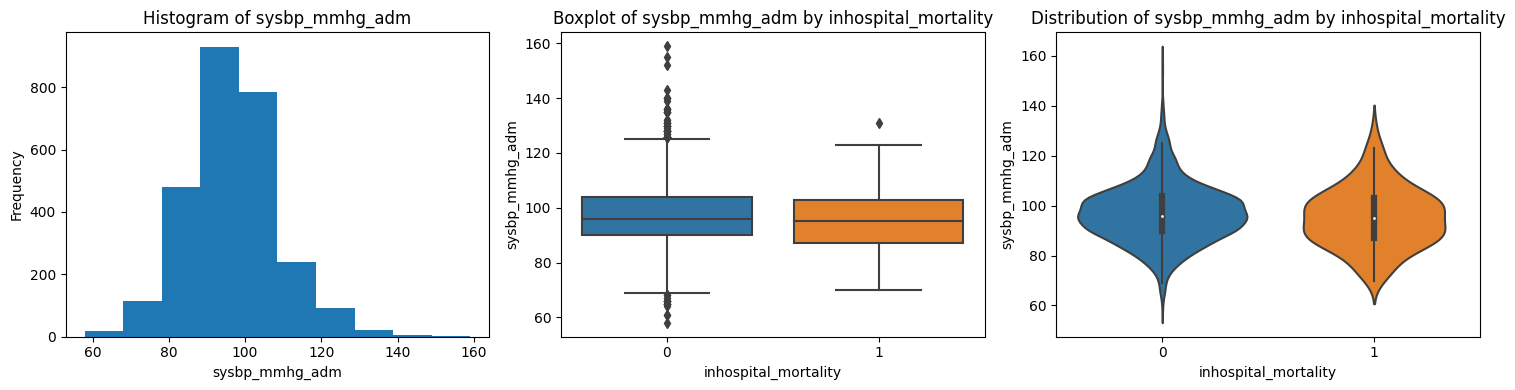

("for 'sysbp_mmhg_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [22]:
#Systolic blood pressure
plots_statistical_analysis('sysbp_mmhg_adm')

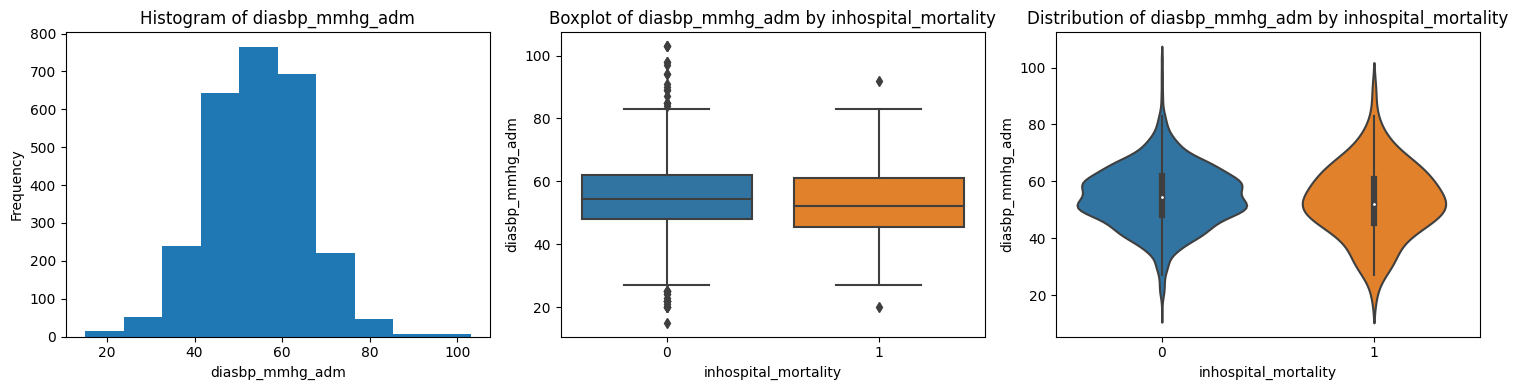

("for 'diasbp_mmhg_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [23]:
#Diastolic blood pressure
plots_statistical_analysis('diasbp_mmhg_adm')

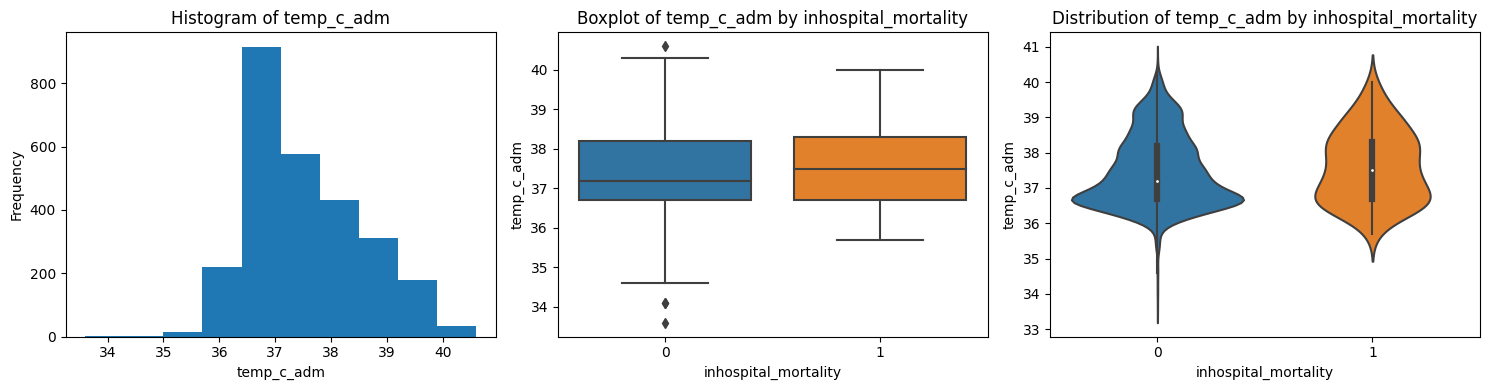

("for 'temp_c_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [24]:
#Axillary temperature (Celsius)
plots_statistical_analysis('temp_c_adm')

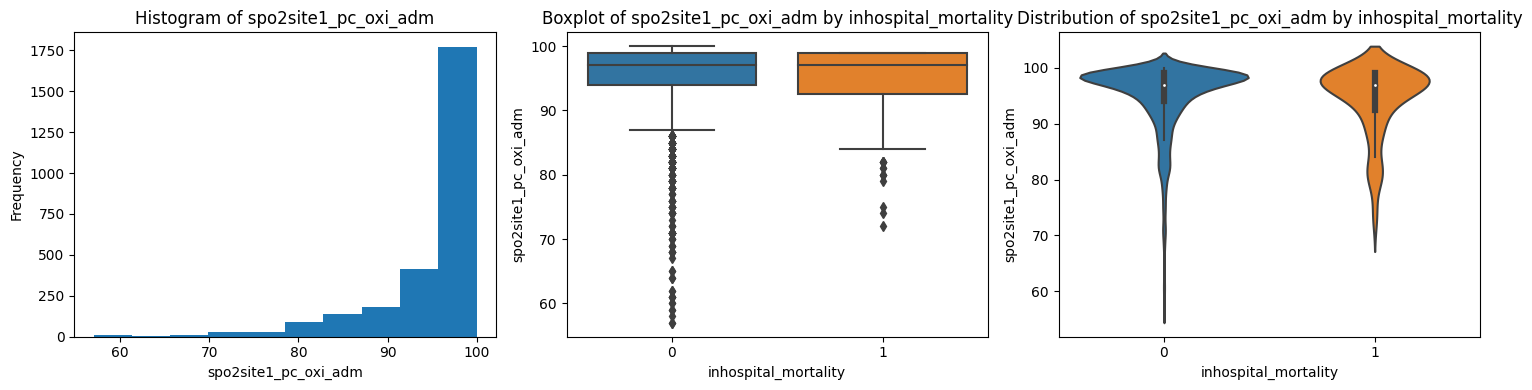

("for 'spo2site1_pc_oxi_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [25]:
#Oxygen saturation (measure 1)
plots_statistical_analysis('spo2site1_pc_oxi_adm')

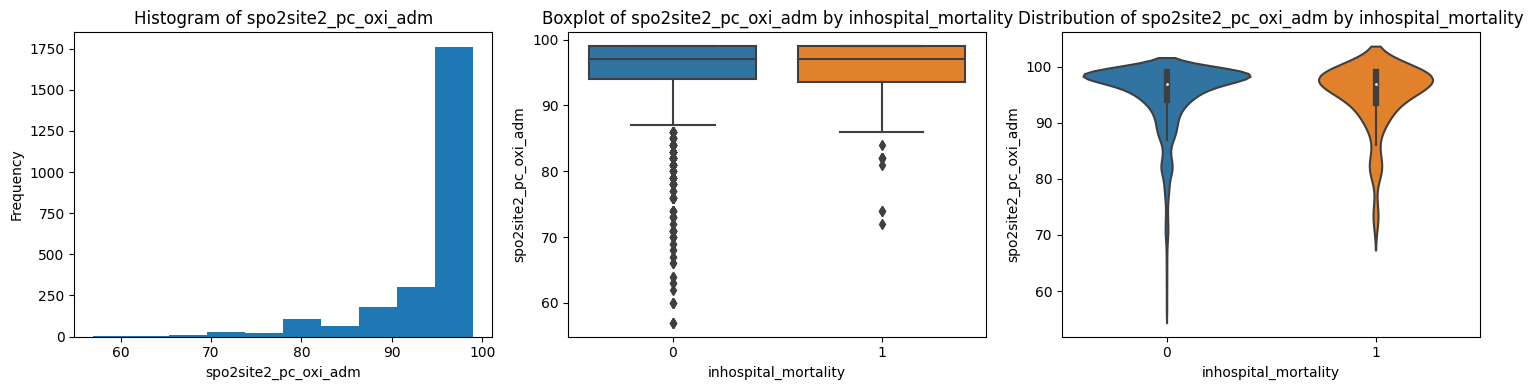

("for 'spo2site2_pc_oxi_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [26]:
#Oxygen saturation (measure 2)
plots_statistical_analysis('spo2site2_pc_oxi_adm')

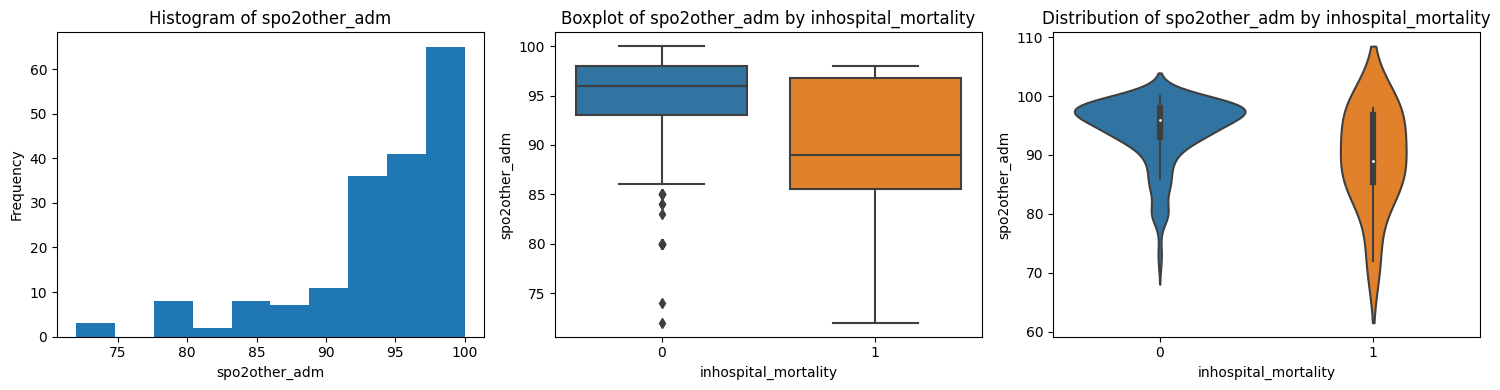

("for 'spo2other_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [27]:
#SpO2 from other device 
plots_statistical_analysis('spo2other_adm')

In [28]:
def plot_categorical(column_name):
    # Calculate the count and percentage of 'Attrition' values for each category in the column
    category_counts = df[column_name].value_counts()
    category_counts_inhospital_mortality = df.groupby(column_name)['inhospital_mortality'].value_counts().unstack().fillna(0)
    category_percentages = (category_counts_inhospital_mortality.T / category_counts_inhospital_mortality.sum(axis=1)).T * 100

    # Plot the percentage of each category in the column based on 'Attrition'
    plt.figure(figsize=(8, 6))
    category_percentages.plot(kind='bar', stacked=True)
    plt.title('Percentage of inhospital_mortality by {}'.format(column_name))
    plt.xlabel('inhospital_mortality')
    plt.ylabel('Percentage')
    plt.legend(loc='lower right')
    plt.show()

<Figure size 800x600 with 0 Axes>

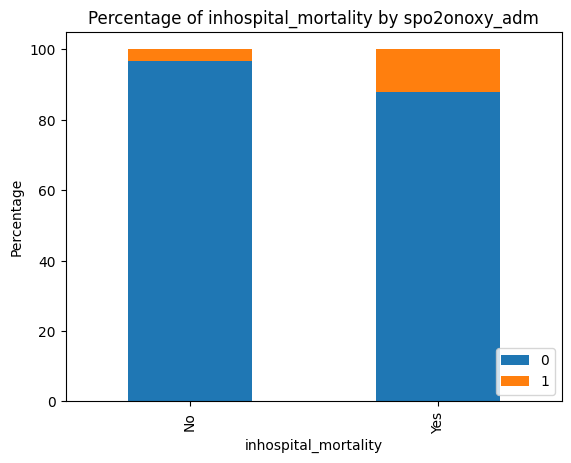

In [29]:
#Was SpO2 measured while on oxygen?
plot_categorical('spo2onoxy_adm')


<Figure size 800x600 with 0 Axes>

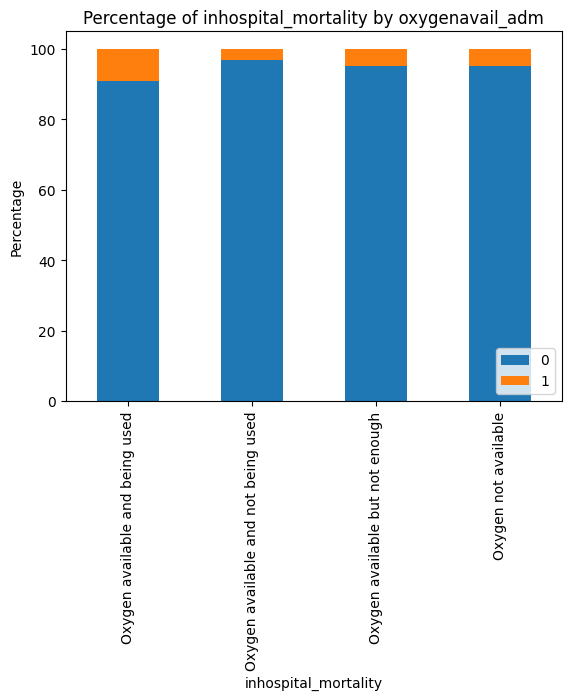

In [30]:
#What is the child's supplementary oxygen status?
plot_categorical('oxygenavail_adm')

<Figure size 800x600 with 0 Axes>

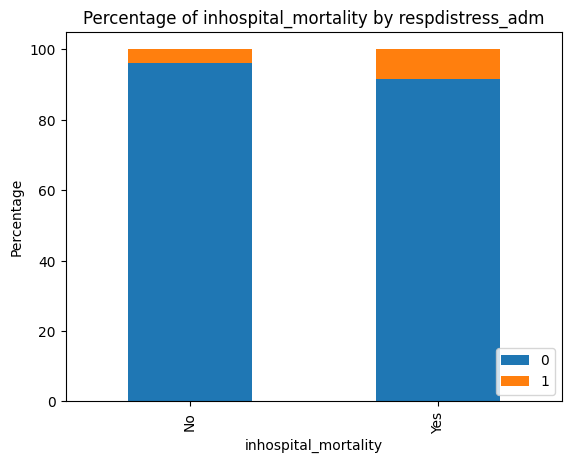

In [31]:
#Does the child have severe respiratory distress (grunting/severe chestindrawing)?
plot_categorical('respdistress_adm')

<Figure size 800x600 with 0 Axes>

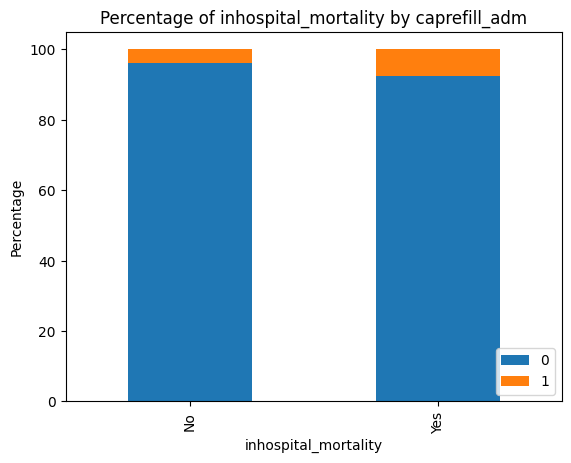

In [32]:
#Does the child have a capillary refill of 3 or more seconds? (to evaluate dehydration, shock, or other conditions affecting blood flow)
plot_categorical('caprefill_adm')

<Figure size 800x600 with 0 Axes>

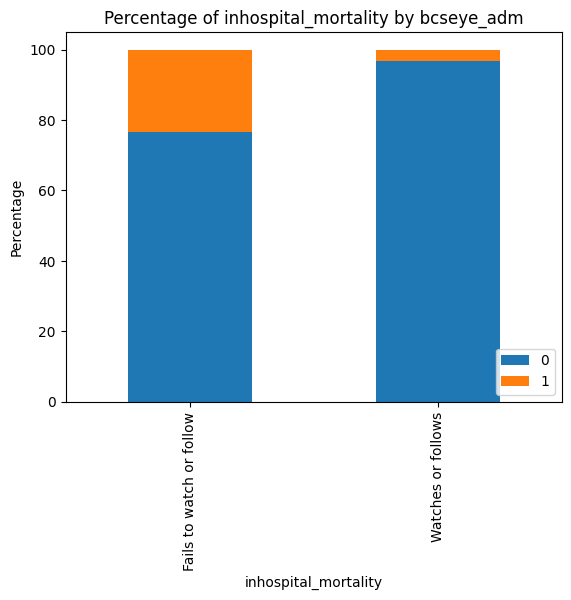

In [33]:
#Eye movement (Blantyre Coma Scale)
plot_categorical('bcseye_adm')

<Figure size 800x600 with 0 Axes>

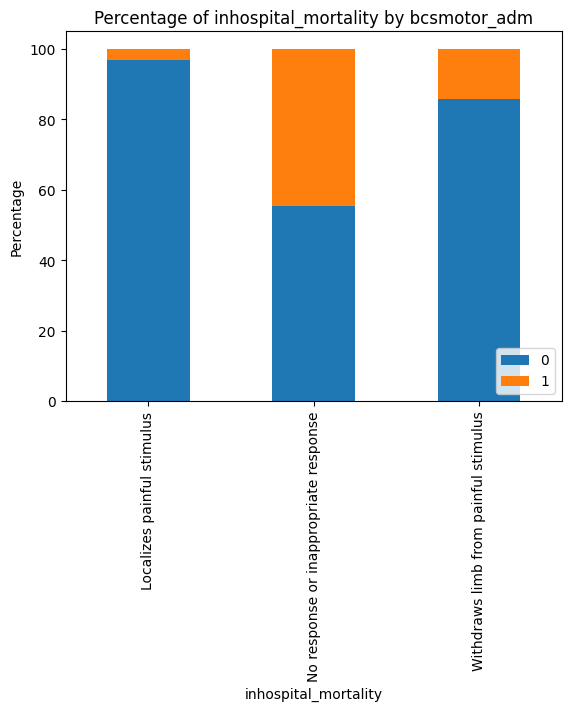

In [34]:
#Best motor response (Blantyre Coma Scale)
plot_categorical('bcsmotor_adm')

<Figure size 800x600 with 0 Axes>

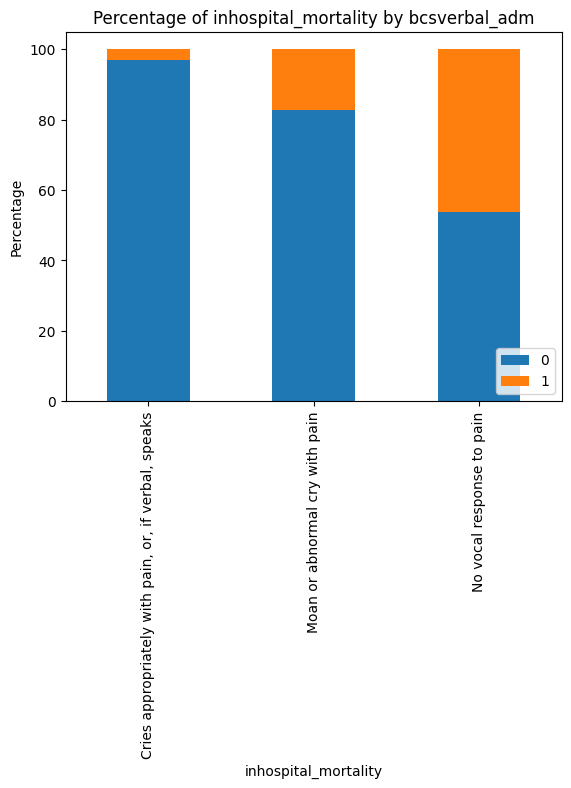

In [35]:
#Best verbal response (Blantyre Coma Scale)
plot_categorical('bcsverbal_adm')

<Figure size 800x600 with 0 Axes>

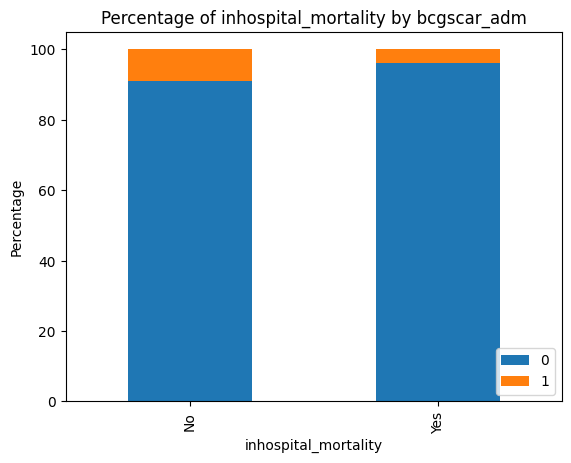

In [36]:
#Has BCG scar (if <6m, verbal report of vaccine OK)?
plot_categorical('bcgscar_adm')

<Figure size 800x600 with 0 Axes>

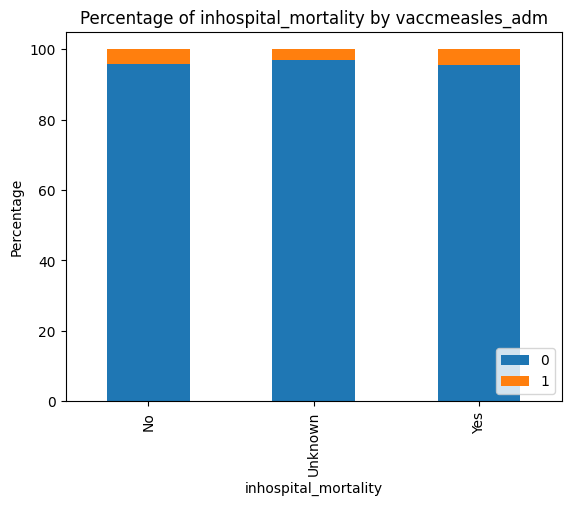

In [37]:
#Has the child received a measles vaccination?
plot_categorical('vaccmeasles_adm')

<Figure size 800x600 with 0 Axes>

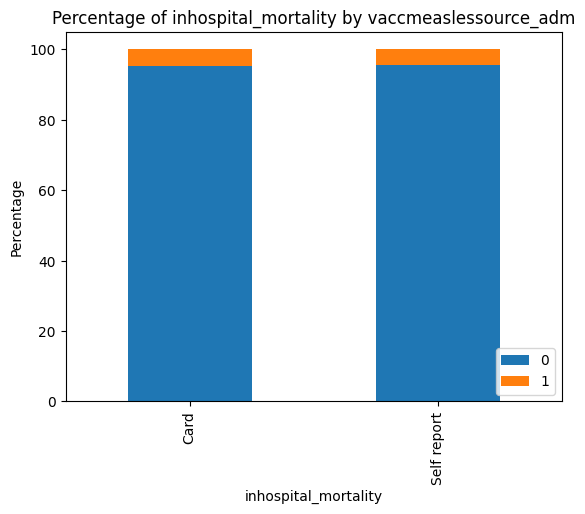

In [38]:
#What is the source of the information regarding measles vaccination?
plot_categorical('vaccmeaslessource_adm')

<Figure size 800x600 with 0 Axes>

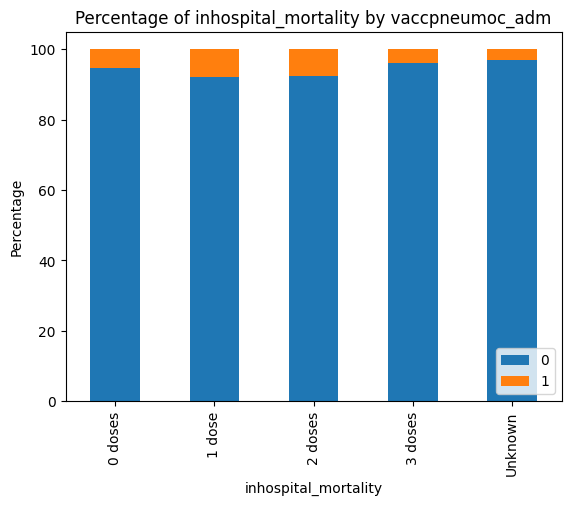

In [39]:
#Has the child received a pneumococcal vaccination?
plot_categorical('vaccpneumoc_adm')

<Figure size 800x600 with 0 Axes>

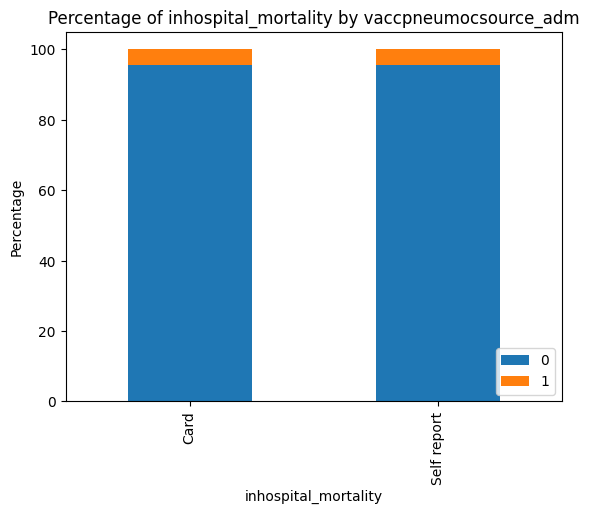

In [40]:
#What is the source of the information regarding pneumococcal vaccination?
plot_categorical('vaccpneumocsource_adm')

Object `vaccination` not found.


<Figure size 800x600 with 0 Axes>

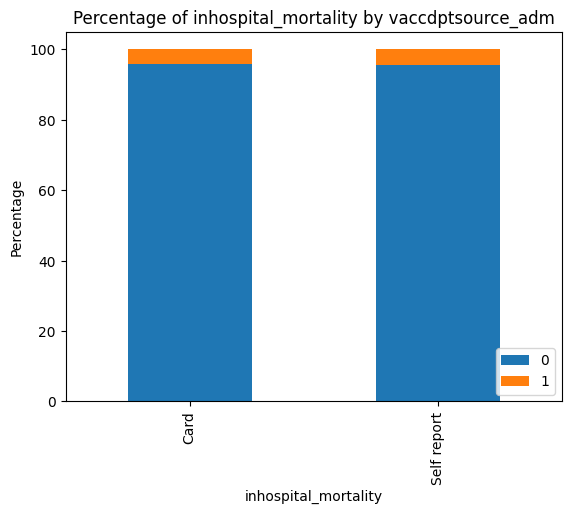

In [41]:
Has the child received a DPT/Penta vaccination?
plot_categorical('vaccdptsource_adm')

<Figure size 800x600 with 0 Axes>

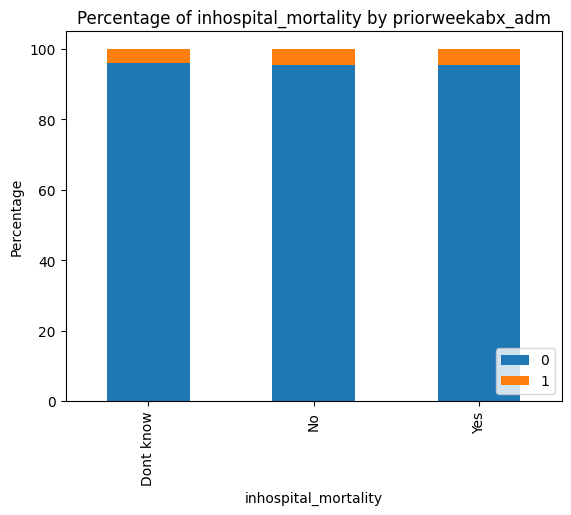

In [42]:
#Has the child used antibiotics in the past week?
plot_categorical('priorweekabx_adm')

<Figure size 800x600 with 0 Axes>

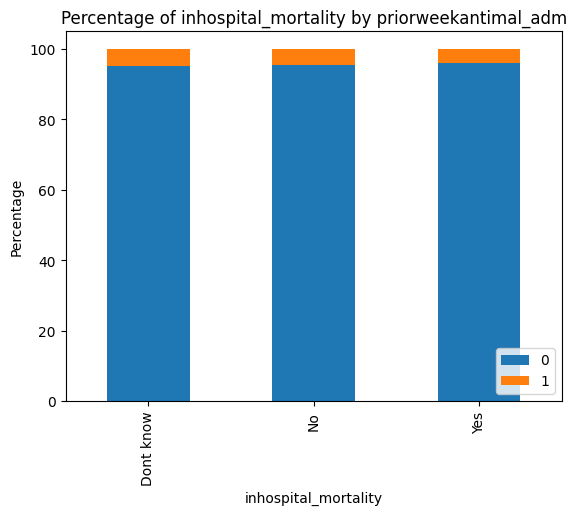

In [43]:
#Has the child used antimalarials in the past week?
plot_categorical('priorweekantimal_adm')

In [44]:
columns_with_symptoms = [col for col in df.columns if 'symptoms' in col.lower()]

print(columns_with_symptoms)

['symptoms_adm___1', 'symptoms_adm___2', 'symptoms_adm___3', 'symptoms_adm___4', 'symptoms_adm___5', 'symptoms_adm___6', 'symptoms_adm___7', 'symptoms_adm___8', 'symptoms_adm___9', 'symptoms_adm___10', 'symptoms_adm___11', 'symptoms_adm___12', 'symptoms_adm___13', 'symptoms_adm___14', 'symptoms_adm___15', 'symptoms_adm___16', 'symptoms_adm___17', 'symptoms_adm___18']


<Figure size 800x600 with 0 Axes>

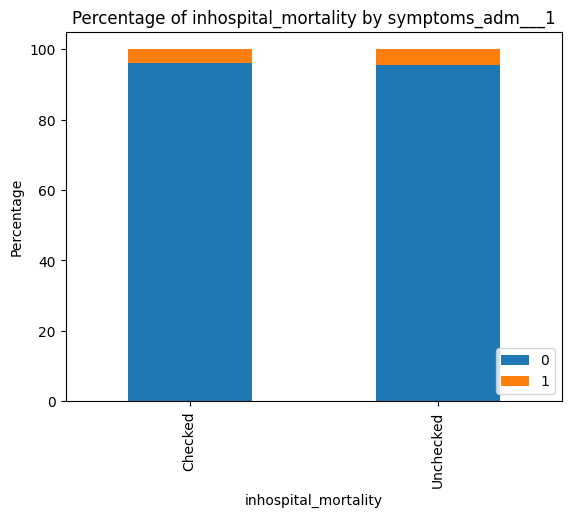

In [45]:
#[Rash]
plot_categorical('symptoms_adm___1')

<Figure size 800x600 with 0 Axes>

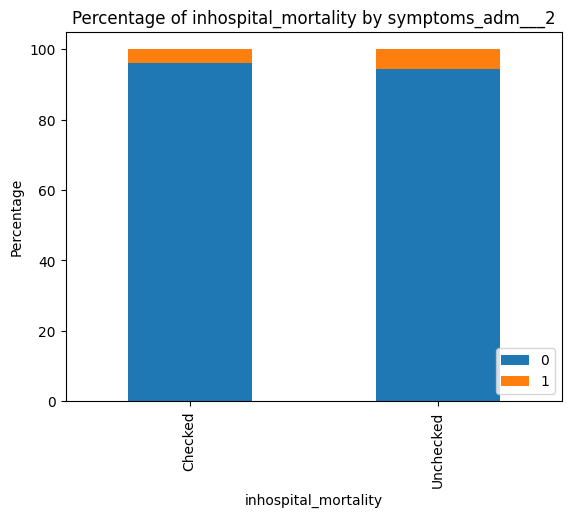

In [46]:
#[Cough < 14 days]
plot_categorical('symptoms_adm___2')

<Figure size 800x600 with 0 Axes>

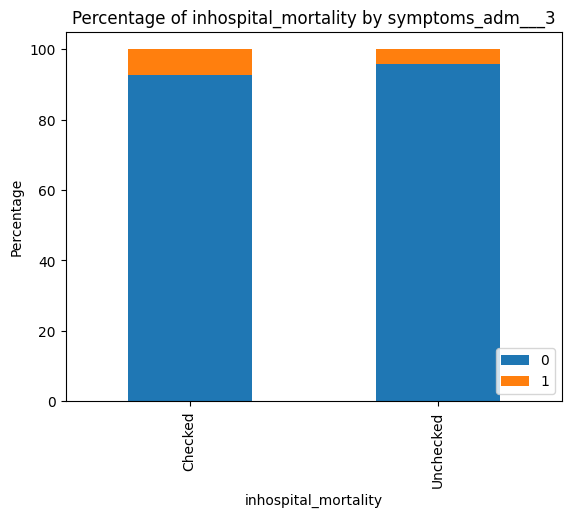

In [47]:
#[Cough >14 days]
plot_categorical('symptoms_adm___3')

<Figure size 800x600 with 0 Axes>

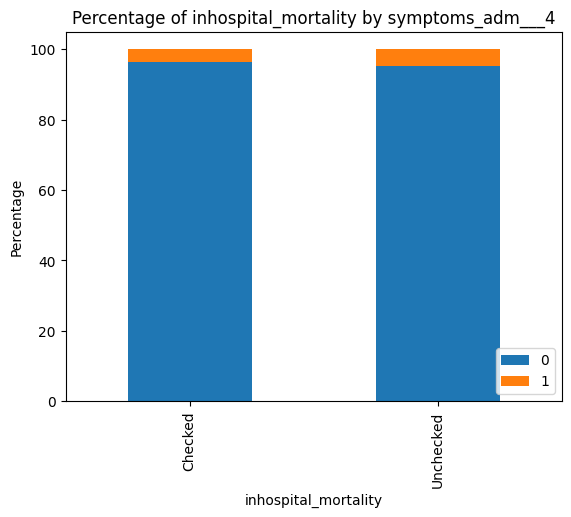

In [48]:
#[Diarrhea < 14 days]
plot_categorical('symptoms_adm___4')

<Figure size 800x600 with 0 Axes>

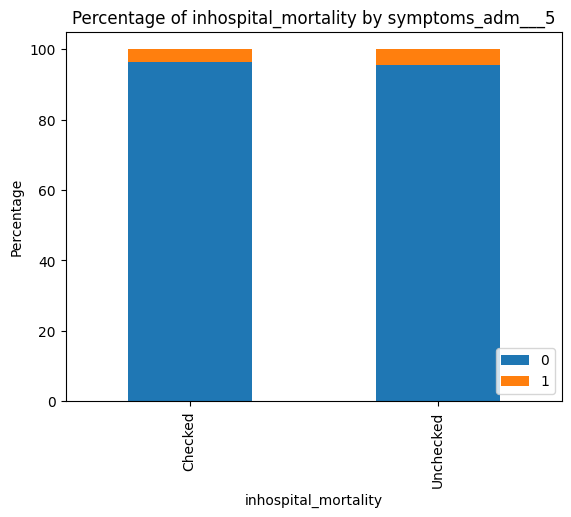

In [49]:
#[Diarrhea >14 days]
plot_categorical('symptoms_adm___5')

<Figure size 800x600 with 0 Axes>

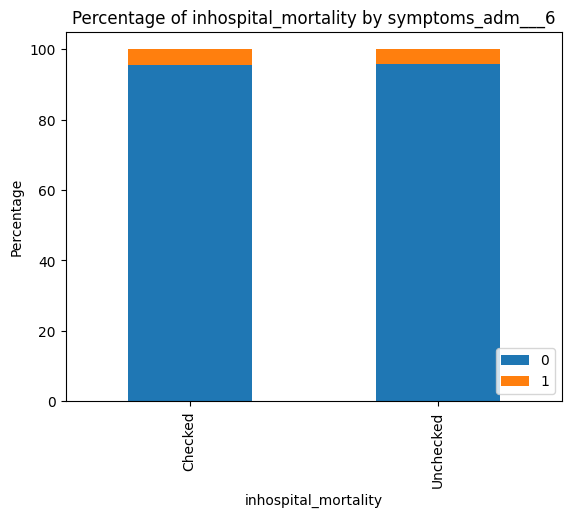

In [50]:
#[Fever/hotness of body <7 days]
plot_categorical('symptoms_adm___6')

<Figure size 800x600 with 0 Axes>

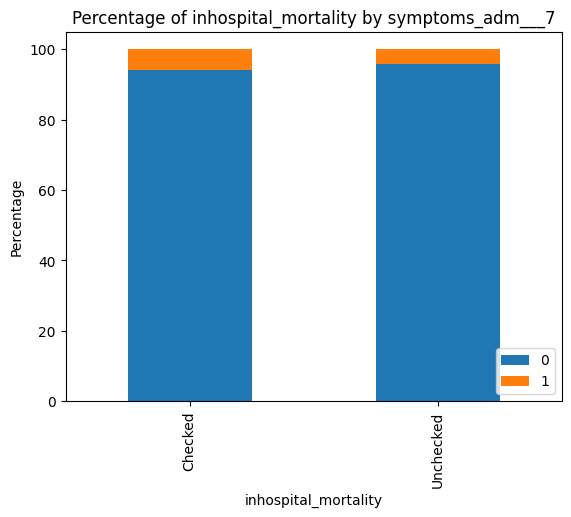

In [51]:
#[Fever/hotness of body>7 days]
plot_categorical('symptoms_adm___7')

<Figure size 800x600 with 0 Axes>

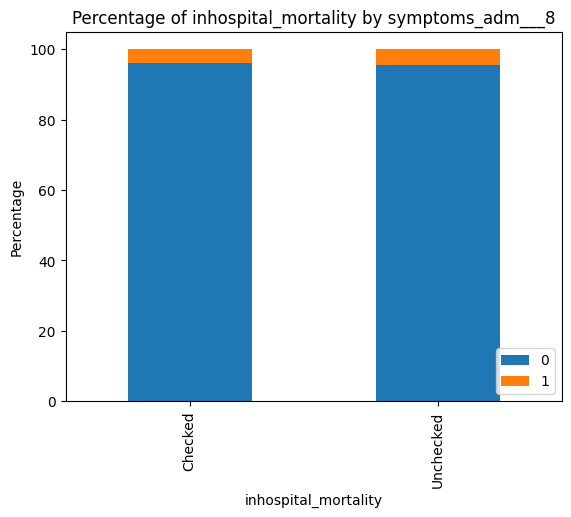

In [52]:
#Vomiting everything
plot_categorical('symptoms_adm___8')

<Figure size 800x600 with 0 Axes>

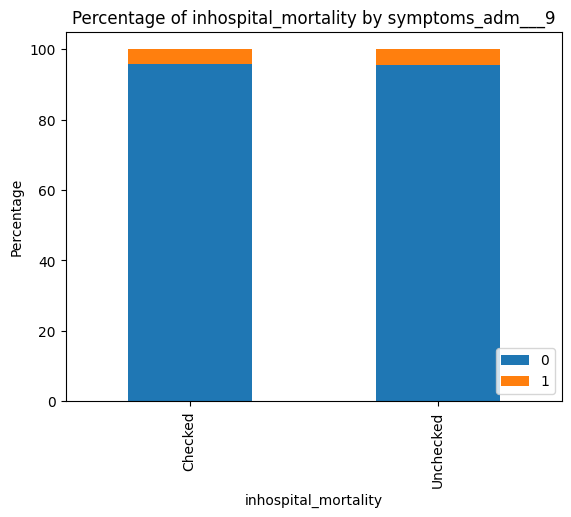

In [53]:
#Abnormally sleepy
plot_categorical('symptoms_adm___9')

<Figure size 800x600 with 0 Axes>

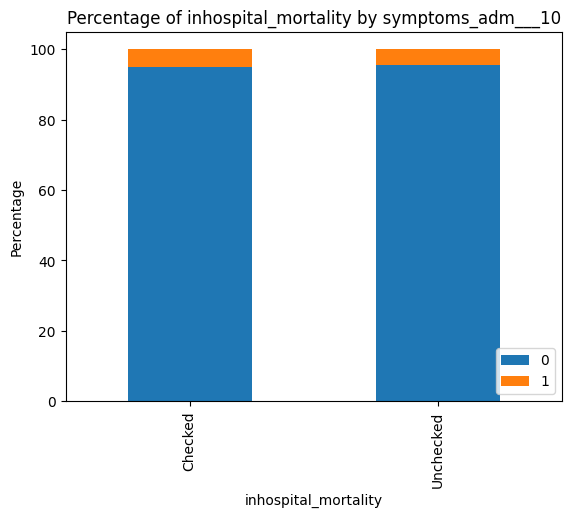

In [54]:
#[Swelling of both feet]
plot_categorical('symptoms_adm___10')

<Figure size 800x600 with 0 Axes>

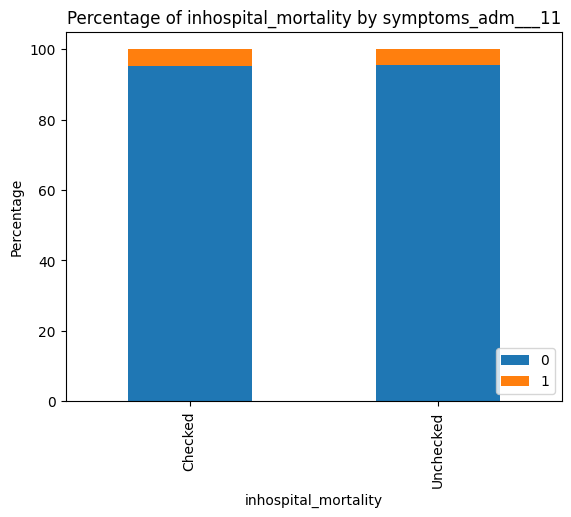

In [55]:
#Changes in urine color
plot_categorical('symptoms_adm___11')

<Figure size 800x600 with 0 Axes>

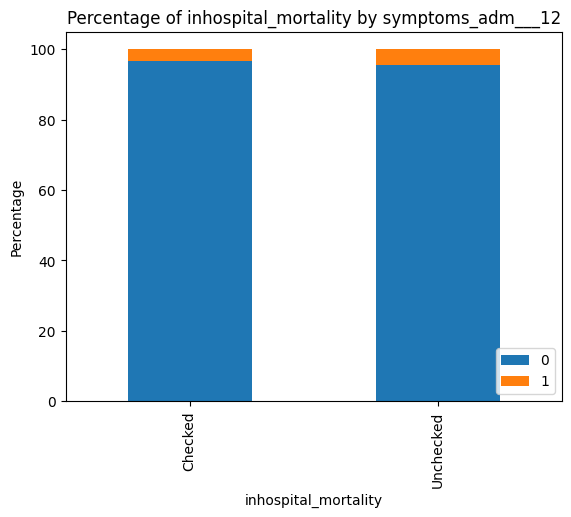

In [56]:
#Making less urine than usual
plot_categorical('symptoms_adm___12')

<Figure size 800x600 with 0 Axes>

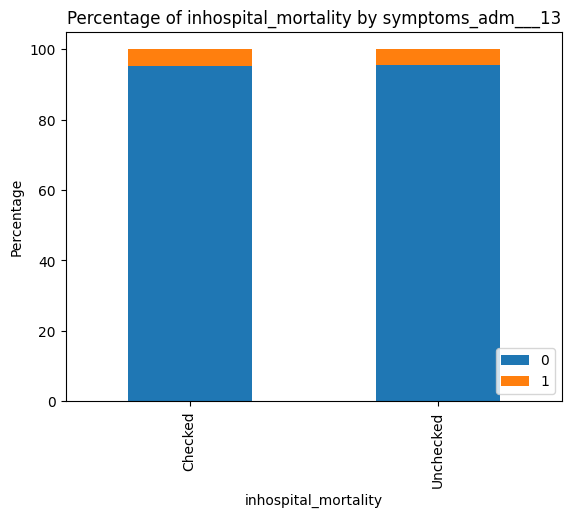

In [57]:
#Blood in stool
plot_categorical('symptoms_adm___13')

<Figure size 800x600 with 0 Axes>

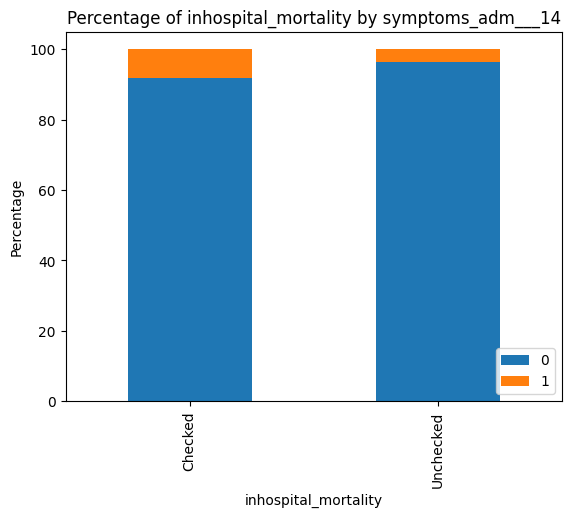

In [58]:
#Seizure/convulsions
plot_categorical('symptoms_adm___14')

<Figure size 800x600 with 0 Axes>

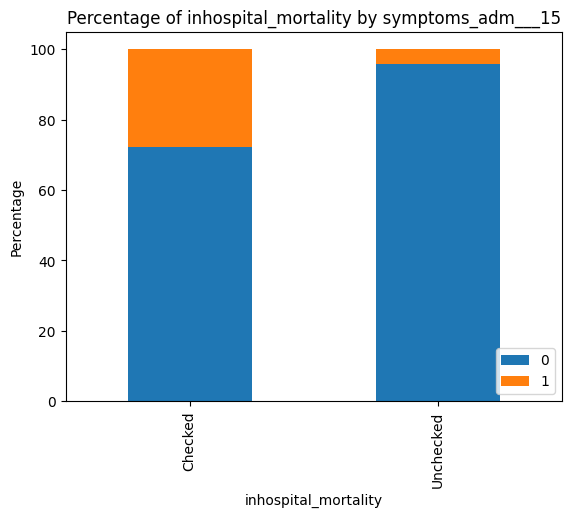

In [59]:
#Coma
plot_categorical('symptoms_adm___15')

<Figure size 800x600 with 0 Axes>

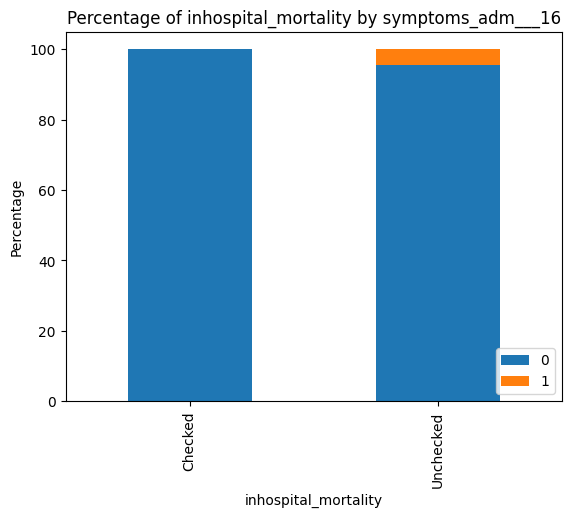

In [60]:
#Yellow soles (if < 2mold)
plot_categorical('symptoms_adm___16')

<Figure size 800x600 with 0 Axes>

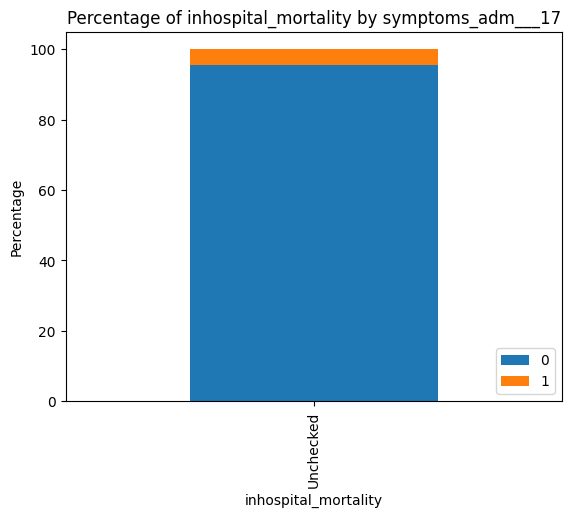

In [61]:
#None
plot_categorical('symptoms_adm___17')

<Figure size 800x600 with 0 Axes>

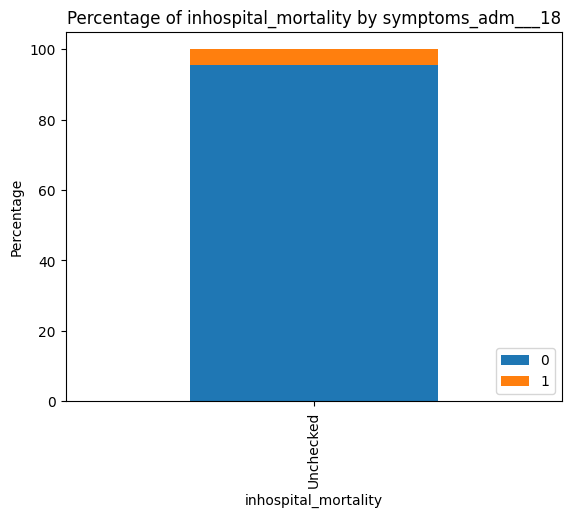

In [62]:
#Don't know
plot_categorical('symptoms_adm___18')

In [63]:
columns_with_symptoms = [col for col in df.columns if 'comorbidity' in col.lower()]

print(columns_with_symptoms)

['comorbidity_adm___1', 'comorbidity_adm___2', 'comorbidity_adm___3', 'comorbidity_adm___4', 'comorbidity_adm___5', 'comorbidity_adm___6', 'comorbidity_adm___7', 'comorbidity_adm___8', 'comorbidity_adm___9', 'comorbidity_adm___10', 'comorbidity_adm___11', 'comorbidity_adm___12']


<Figure size 800x600 with 0 Axes>

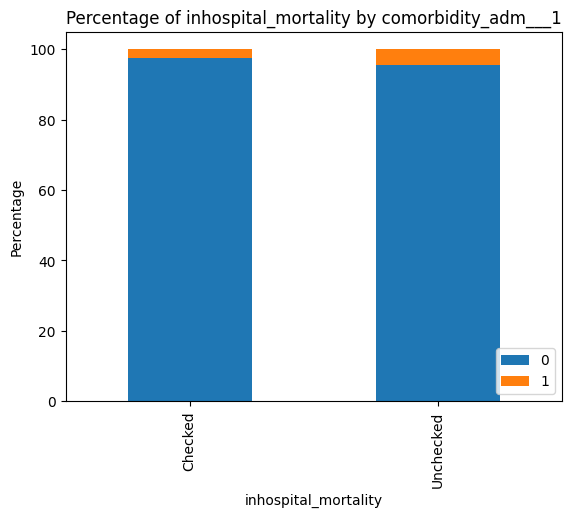

In [64]:
#Reactive airway disease/asthma/allergy
plot_categorical('comorbidity_adm___1')
                 

<Figure size 800x600 with 0 Axes>

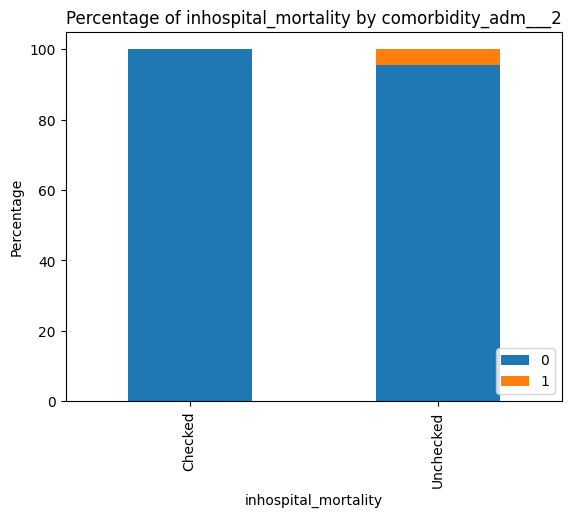

In [65]:
#Oncologic disease
plot_categorical('comorbidity_adm___2')

<Figure size 800x600 with 0 Axes>

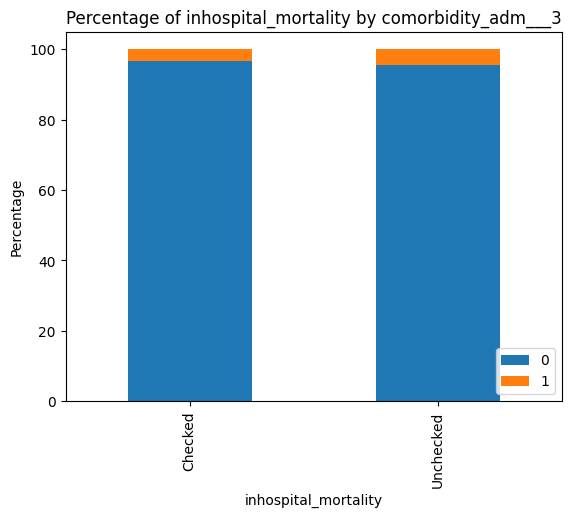

In [66]:
#Cardiac disease
plot_categorical('comorbidity_adm___3')

<Figure size 800x600 with 0 Axes>

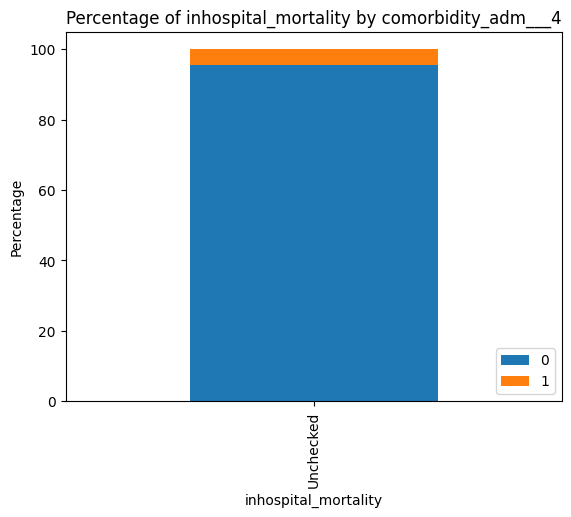

In [67]:
#Endocrine disease (like diabetes)
plot_categorical('comorbidity_adm___4')

<Figure size 800x600 with 0 Axes>

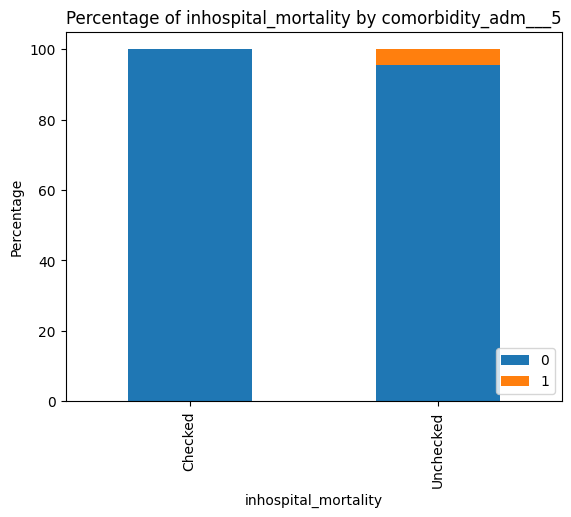

In [68]:
#Sickle cell disease
plot_categorical('comorbidity_adm___5')

<Figure size 800x600 with 0 Axes>

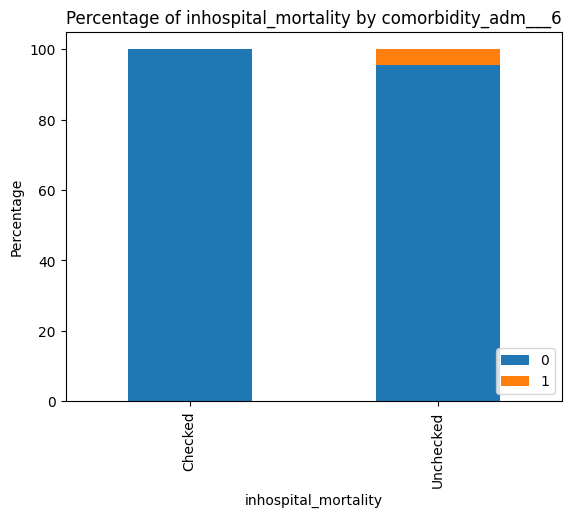

In [69]:
#Tuberculosis
plot_categorical('comorbidity_adm___6')

<Figure size 800x600 with 0 Axes>

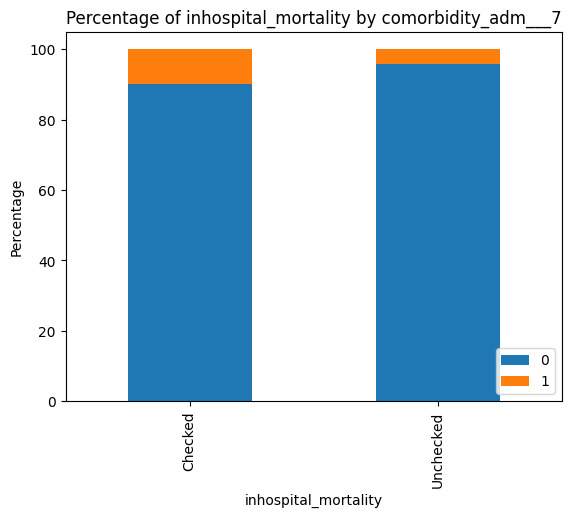

In [70]:
#Physical/mental/developmental disability
plot_categorical('comorbidity_adm___7')

<Figure size 800x600 with 0 Axes>

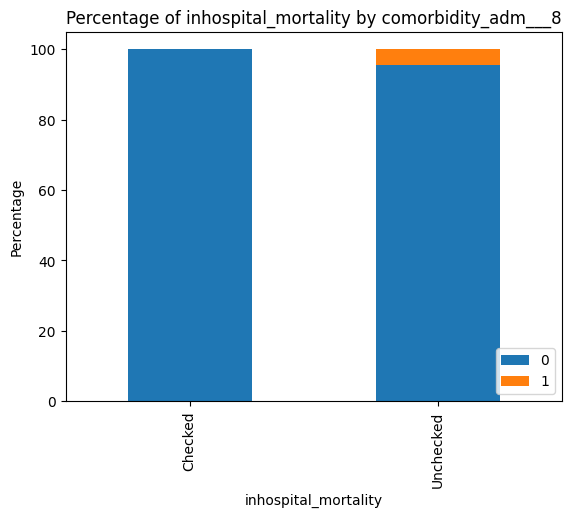

In [71]:
#Hydrocephalus
plot_categorical('comorbidity_adm___8')

<Figure size 800x600 with 0 Axes>

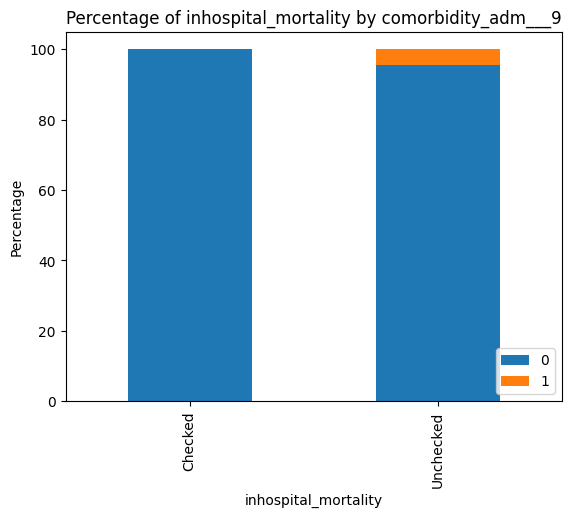

In [72]:
#Trauma/injury
plot_categorical('comorbidity_adm___9')

<Figure size 800x600 with 0 Axes>

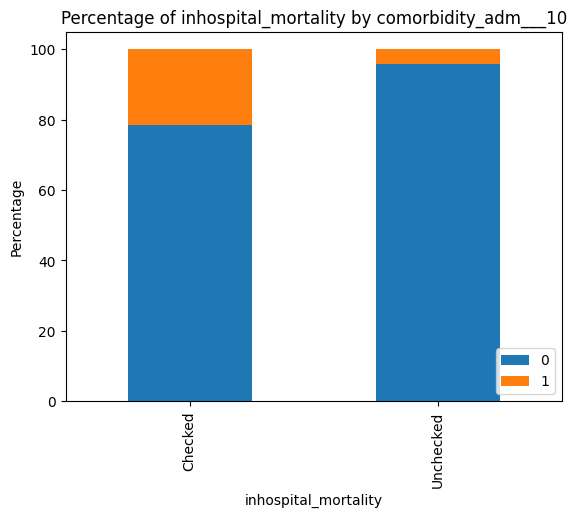

In [73]:
#Other co-morbidity
plot_categorical('comorbidity_adm___10')

<Figure size 800x600 with 0 Axes>

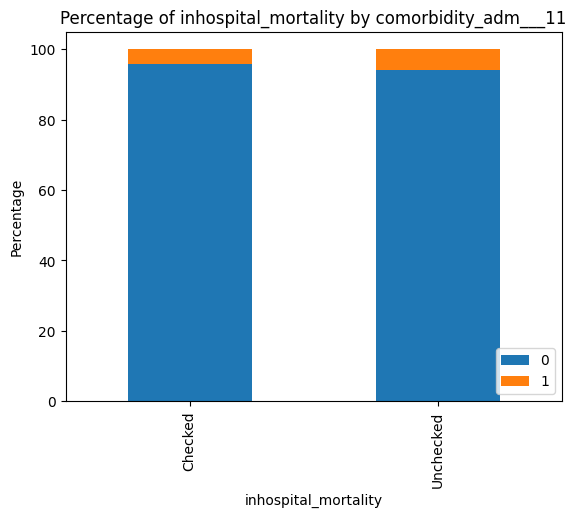

In [74]:
#None
plot_categorical('comorbidity_adm___11')

<Figure size 800x600 with 0 Axes>

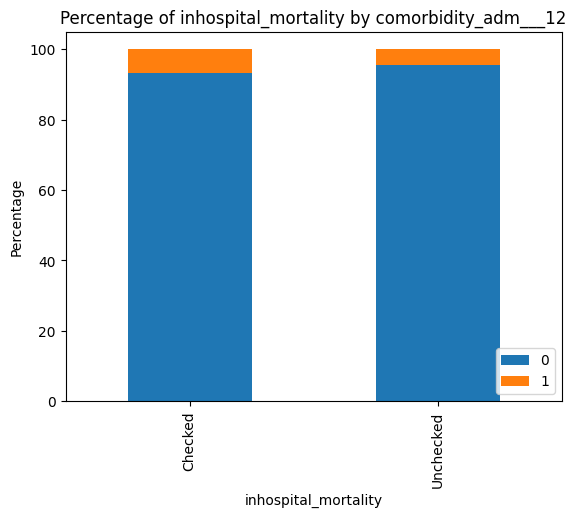

In [75]:
#Don't know
plot_categorical('comorbidity_adm___12')

<Figure size 800x600 with 0 Axes>

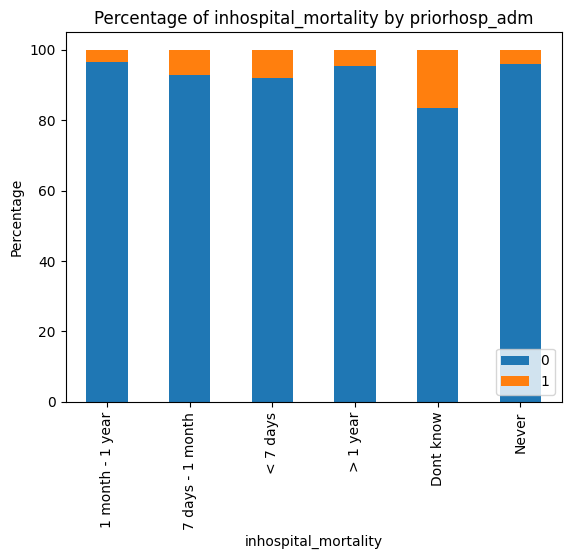

In [76]:
#How long has it been since your child's last hospitalization?
plot_categorical('priorhosp_adm')

<Figure size 800x600 with 0 Axes>

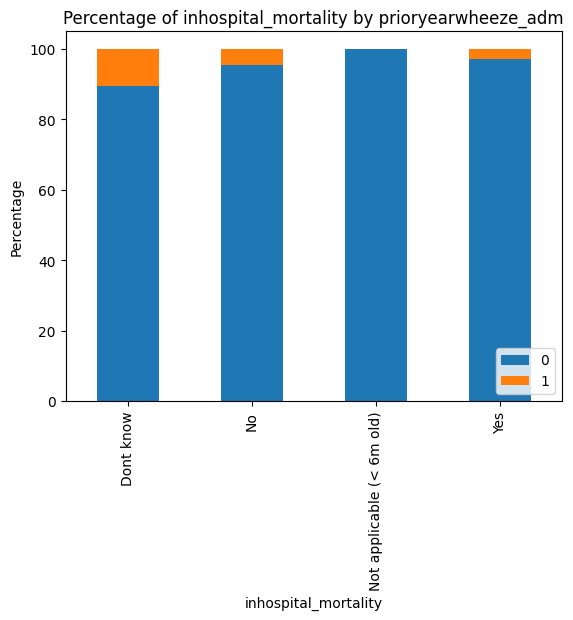

In [77]:
#Prior to this illness, has your child had wheezing in the last year?
plot_categorical('prioryearwheeze_adm')

<Figure size 800x600 with 0 Axes>

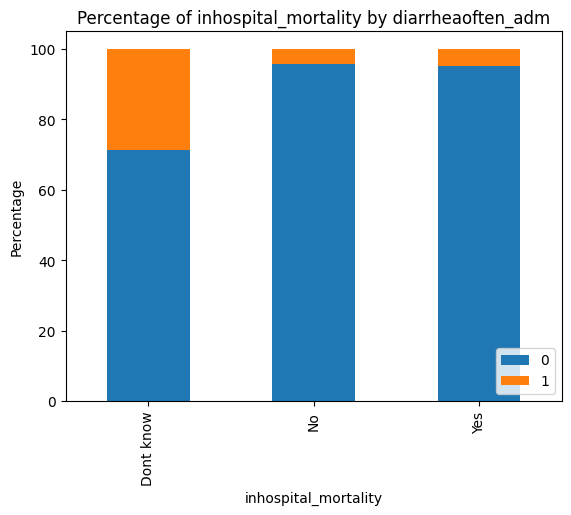

In [78]:
#Does your child have diarrhea often?
plot_categorical('diarrheaoften_adm')

<Figure size 800x600 with 0 Axes>

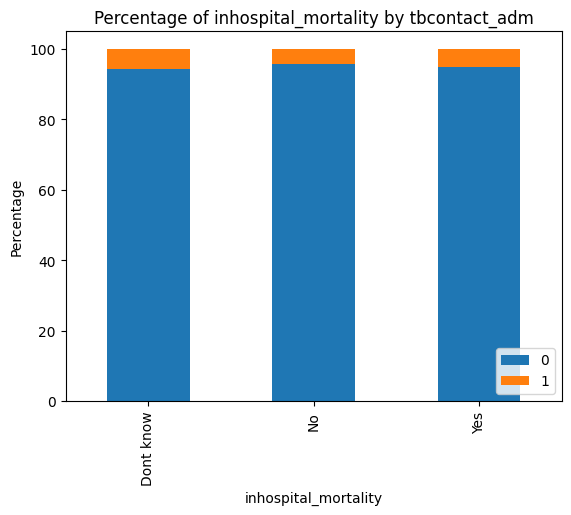

In [79]:
#Does anyone living with the child have chronic cough, frequent fevers or weight loss?
plot_categorical('tbcontact_adm')

<Figure size 800x600 with 0 Axes>

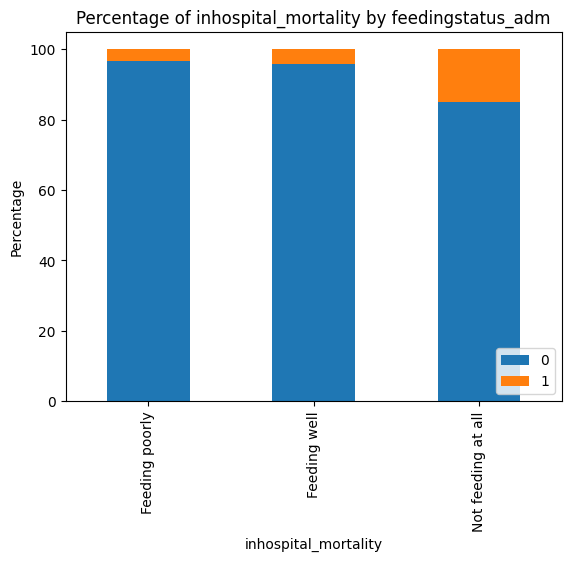

In [80]:
#Current feeding/drinking status (for both breastfed and non-breastfed subjects)?
plot_categorical('feedingstatus_adm')

<Figure size 800x600 with 0 Axes>

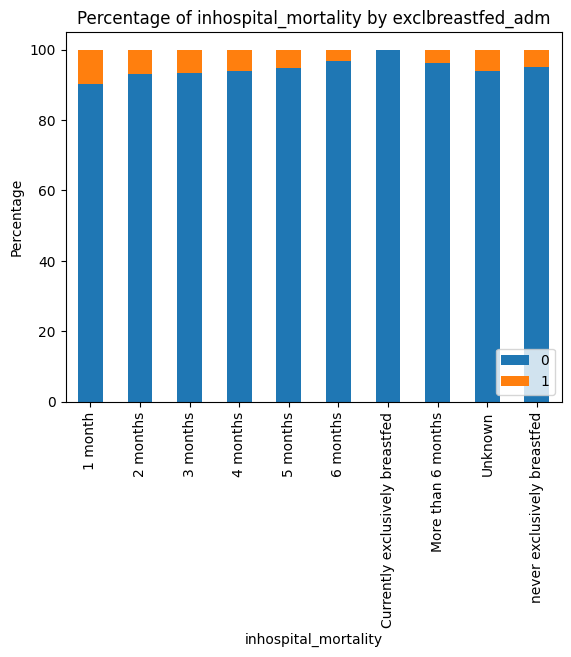

In [81]:
#For how many months was this child exclusively breastfed (months)?
plot_categorical('exclbreastfed_adm')

<Figure size 800x600 with 0 Axes>

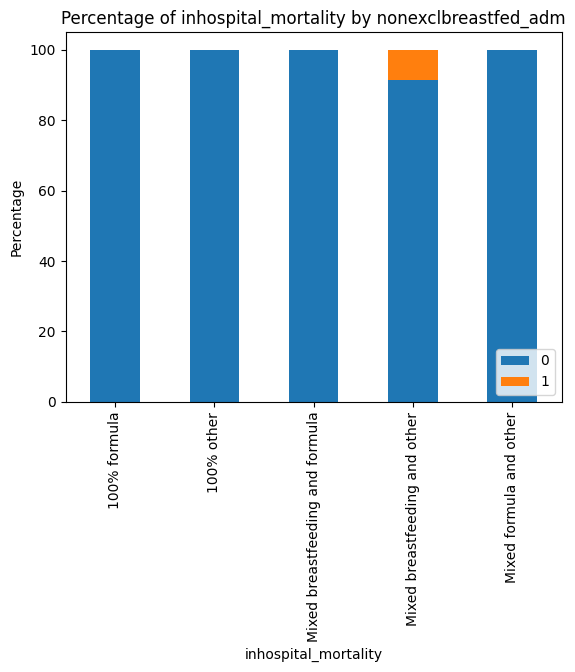

In [82]:
#Non-exclusive breastfeeding details
plot_categorical('nonexclbreastfed_adm')

<Figure size 800x600 with 0 Axes>

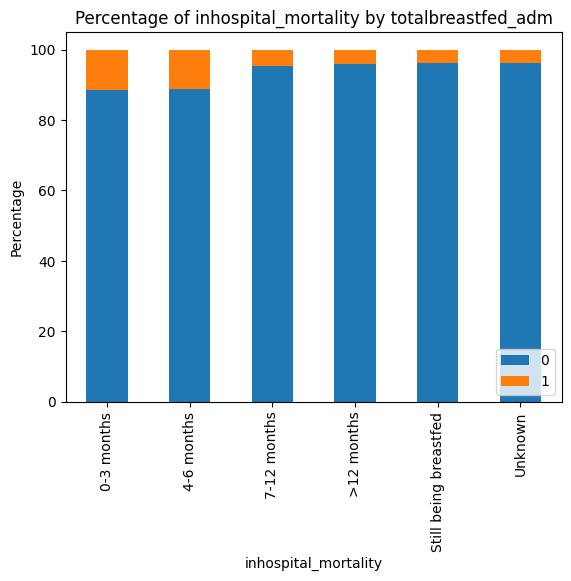

In [83]:
#How long was your child breastfed in total?
plot_categorical('totalbreastfed_adm')

<Figure size 800x600 with 0 Axes>

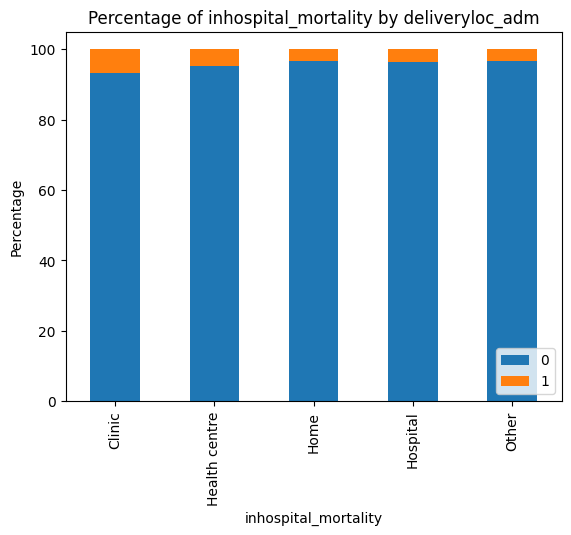

In [84]:
#Where was your child born?
plot_categorical('deliveryloc_adm')

<Figure size 800x600 with 0 Axes>

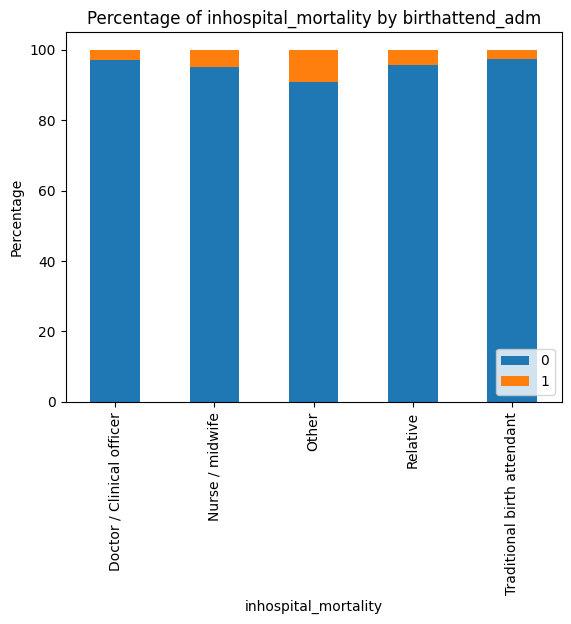

In [85]:
#Did anyone help with the birth of your child?
plot_categorical('birthattend_adm')

<Figure size 800x600 with 0 Axes>

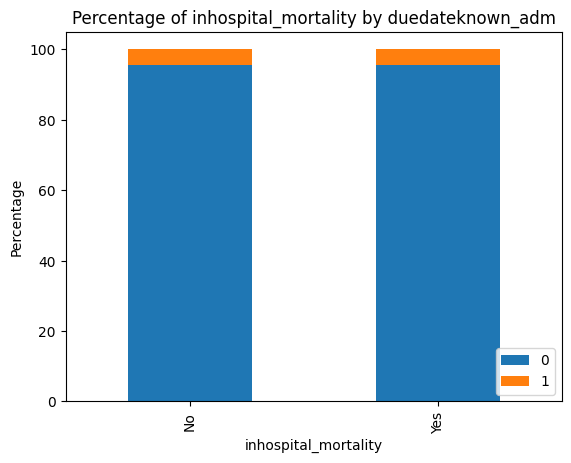

In [86]:
#Do you remember the due date of this child?
plot_categorical('duedateknown_adm')

In [87]:
columns_with_symptoms = [col for col in df.columns if 'birthdetail' in col.lower()]

print(columns_with_symptoms)

['birthdetail_adm___1', 'birthdetail_adm___2', 'birthdetail_adm___3', 'birthdetail_adm___4', 'birthdetail_adm___5', 'birthdetail_adm___6']


<Figure size 800x600 with 0 Axes>

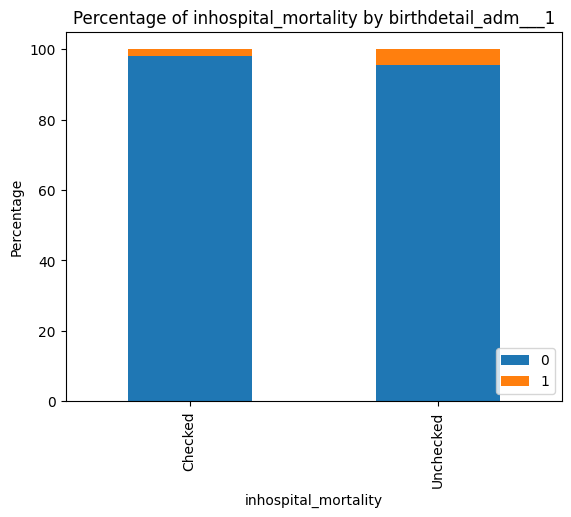

In [88]:
#Premature
plot_categorical('birthdetail_adm___1')

<Figure size 800x600 with 0 Axes>

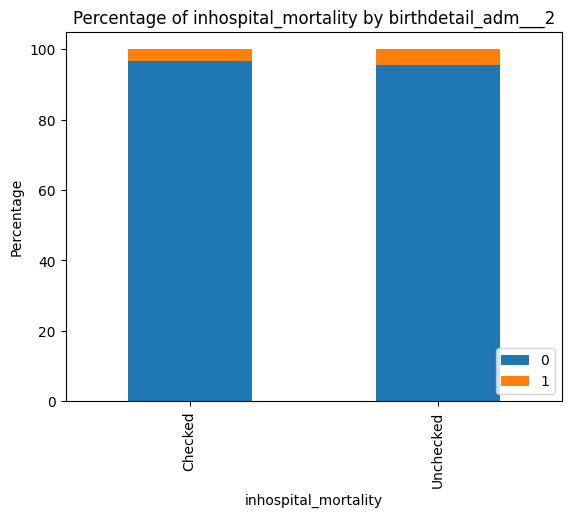

In [89]:
#Born small (<2500g)
plot_categorical('birthdetail_adm___2')

<Figure size 800x600 with 0 Axes>

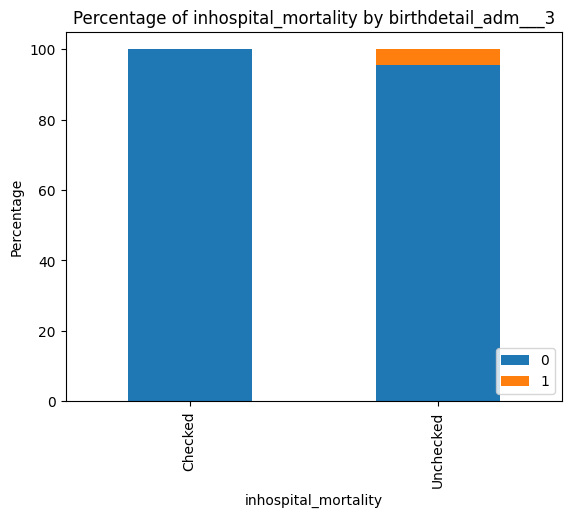

In [90]:
#Born small (weight not known)
plot_categorical('birthdetail_adm___3')

<Figure size 800x600 with 0 Axes>

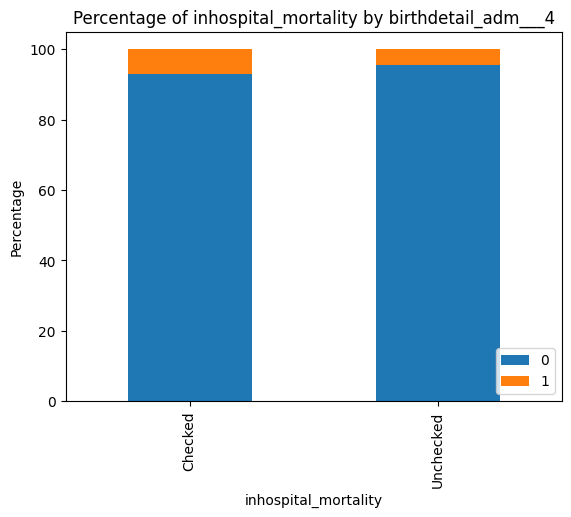

In [91]:
#Twin/multiple birth
plot_categorical('birthdetail_adm___4')

<Figure size 800x600 with 0 Axes>

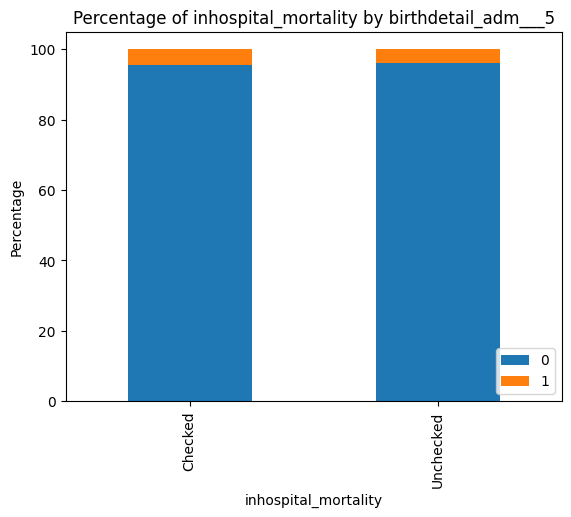

In [92]:
#Born at term
plot_categorical('birthdetail_adm___5')

<Figure size 800x600 with 0 Axes>

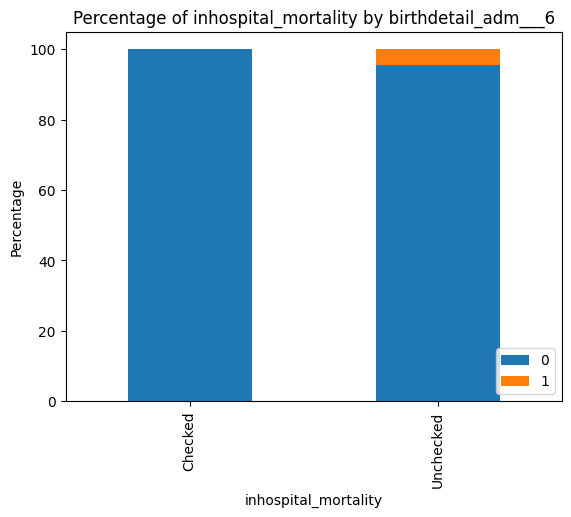

In [93]:
#Don't know
plot_categorical('birthdetail_adm___6')

<Figure size 800x600 with 0 Axes>

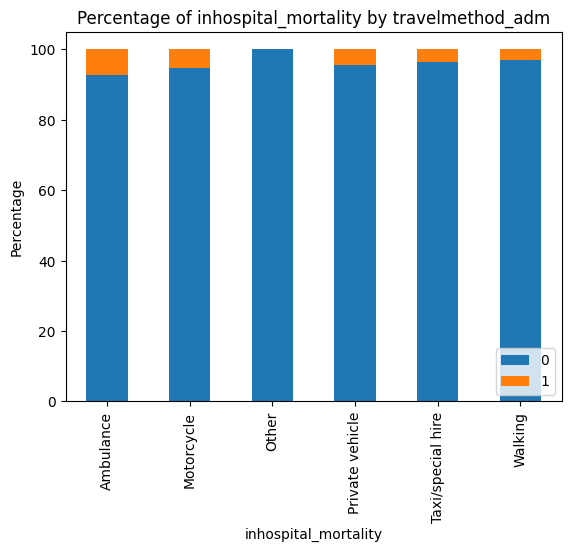

In [94]:
plot_categorical('travelmethod_adm')

<Figure size 800x600 with 0 Axes>

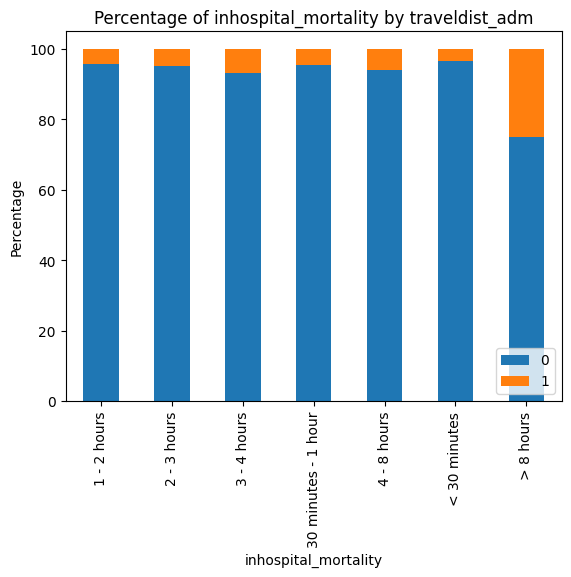

In [95]:
plot_categorical('traveldist_adm')

<Figure size 800x600 with 0 Axes>

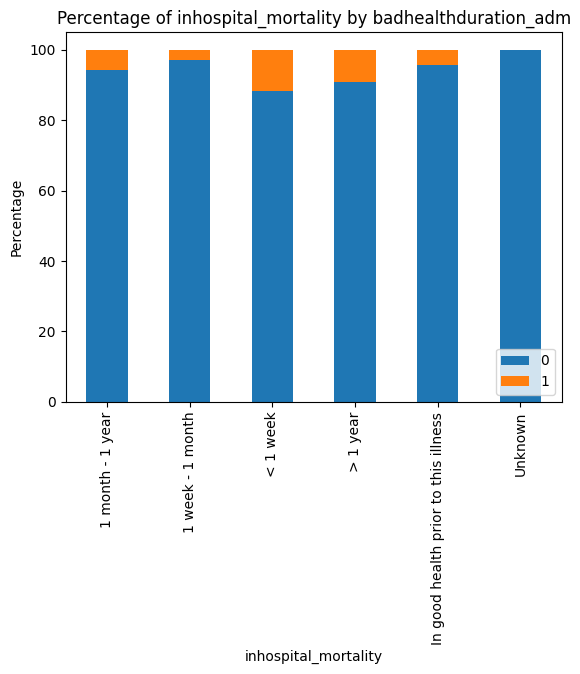

In [96]:
plot_categorical('badhealthduration_adm')

<Figure size 800x600 with 0 Axes>

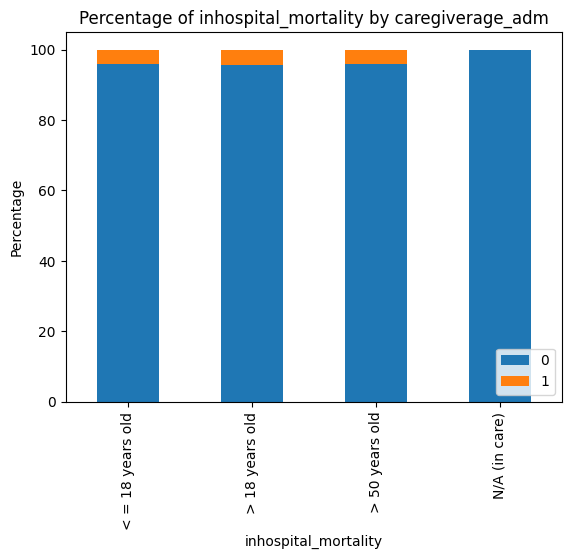

In [97]:
plot_categorical('caregiverage_adm')

<Figure size 800x600 with 0 Axes>

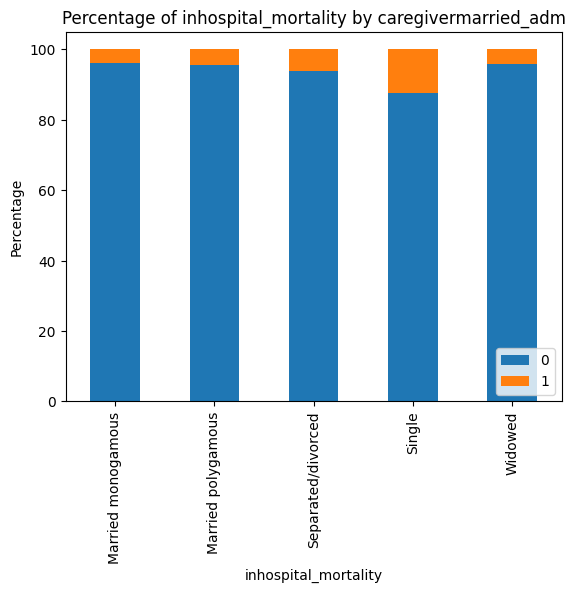

In [98]:
plot_categorical('caregivermarried_adm')

<Figure size 800x600 with 0 Axes>

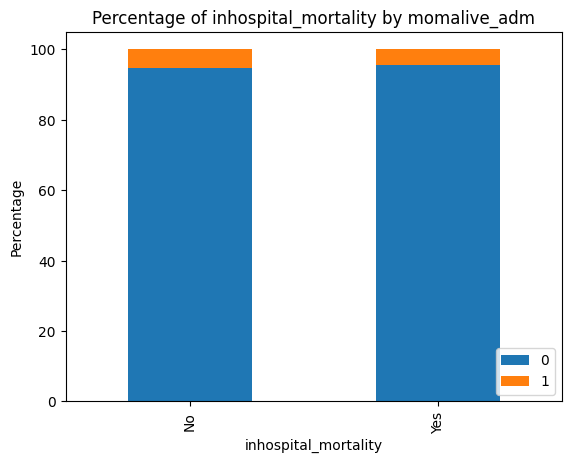

In [99]:
plot_categorical('momalive_adm')

<Figure size 800x600 with 0 Axes>

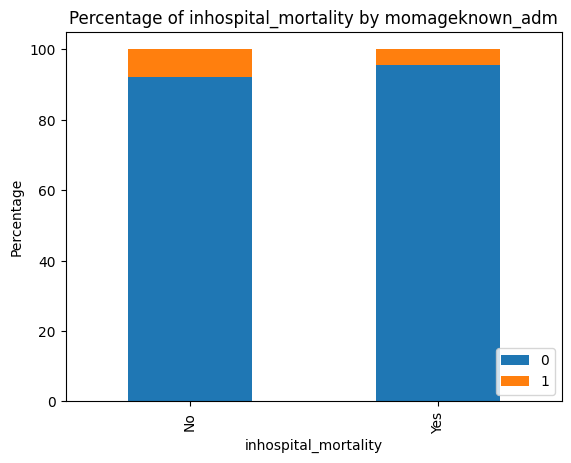

In [100]:
plot_categorical('momageknown_adm')

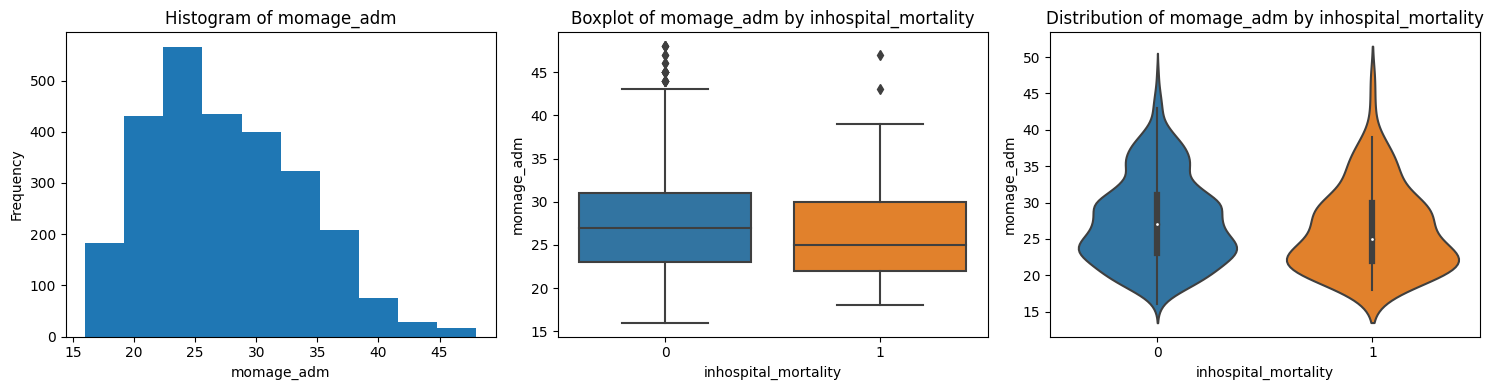

("for 'momage_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [101]:
plots_statistical_analysis('momage_adm')

<Figure size 800x600 with 0 Axes>

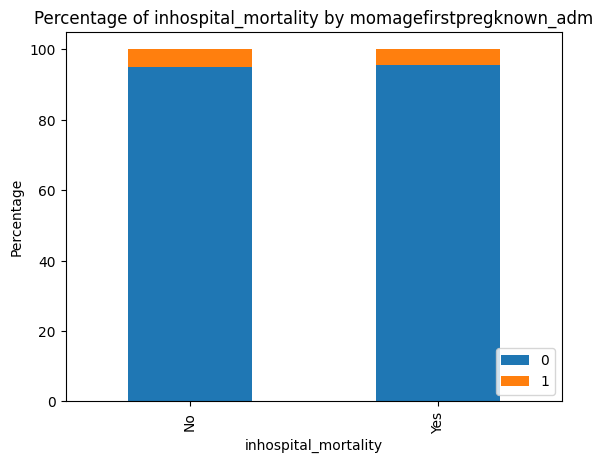

In [102]:
plot_categorical('momagefirstpregknown_adm')

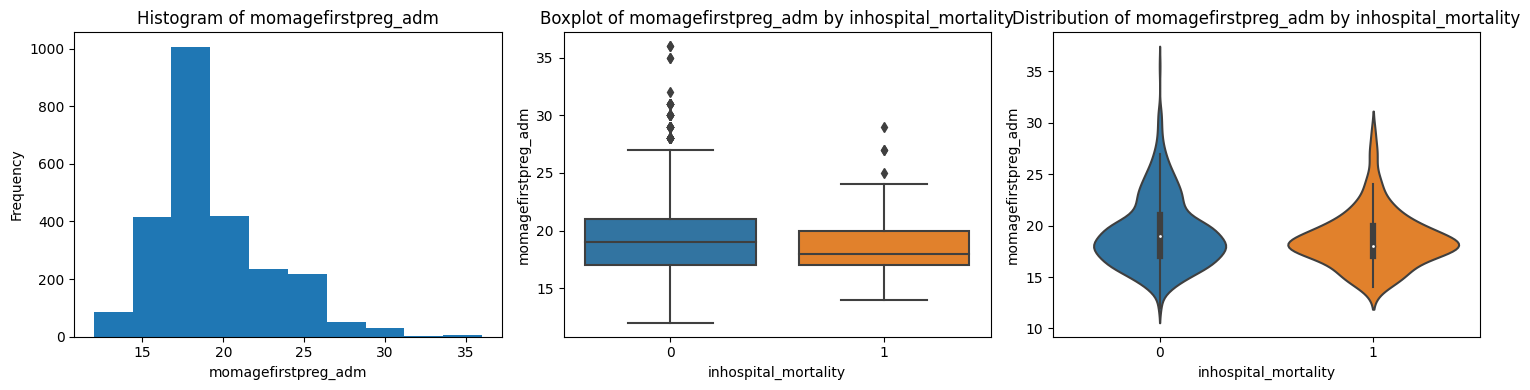

("for 'momagefirstpreg_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [103]:
plots_statistical_analysis('momagefirstpreg_adm')

<Figure size 800x600 with 0 Axes>

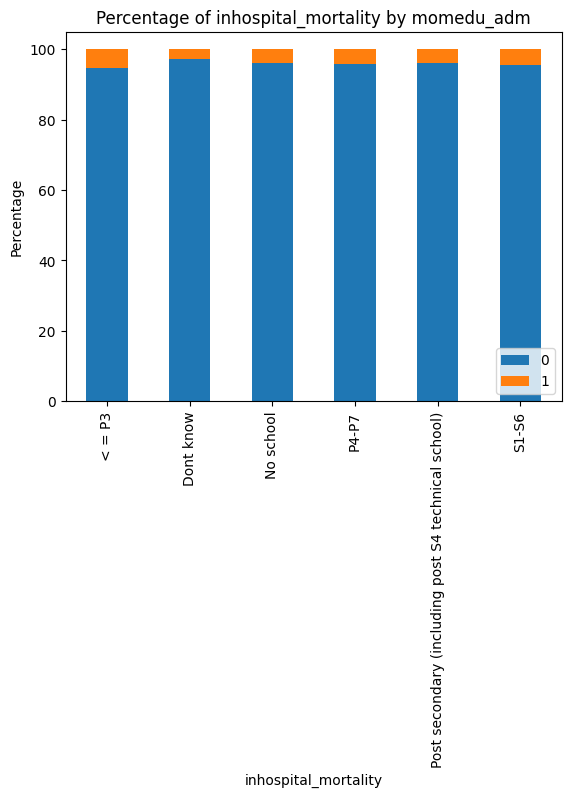

In [104]:
plot_categorical('momedu_adm')


<Figure size 800x600 with 0 Axes>

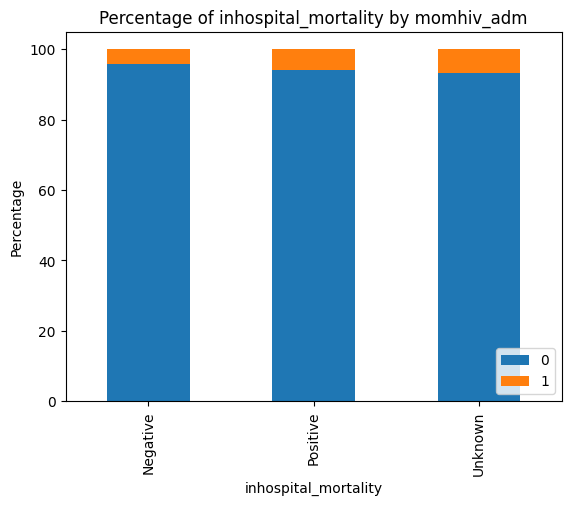

In [105]:
plot_categorical('momhiv_adm')


<Figure size 800x600 with 0 Axes>

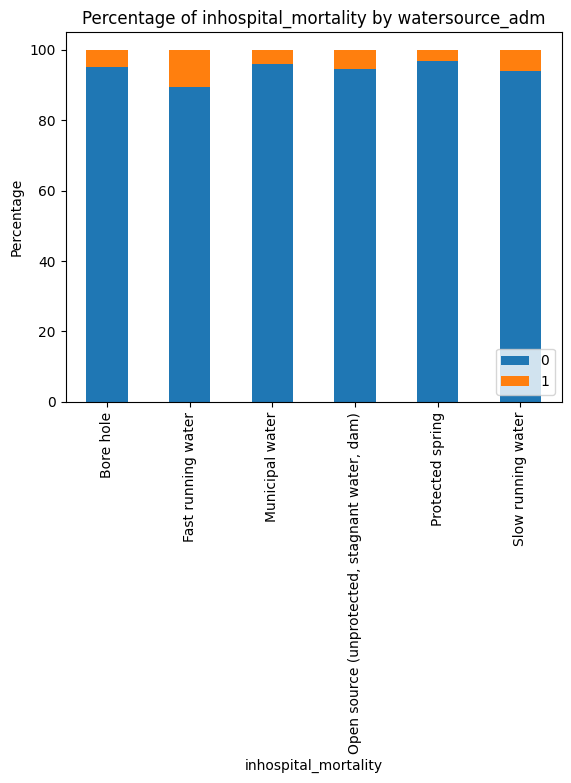

In [106]:
plot_categorical('watersource_adm')


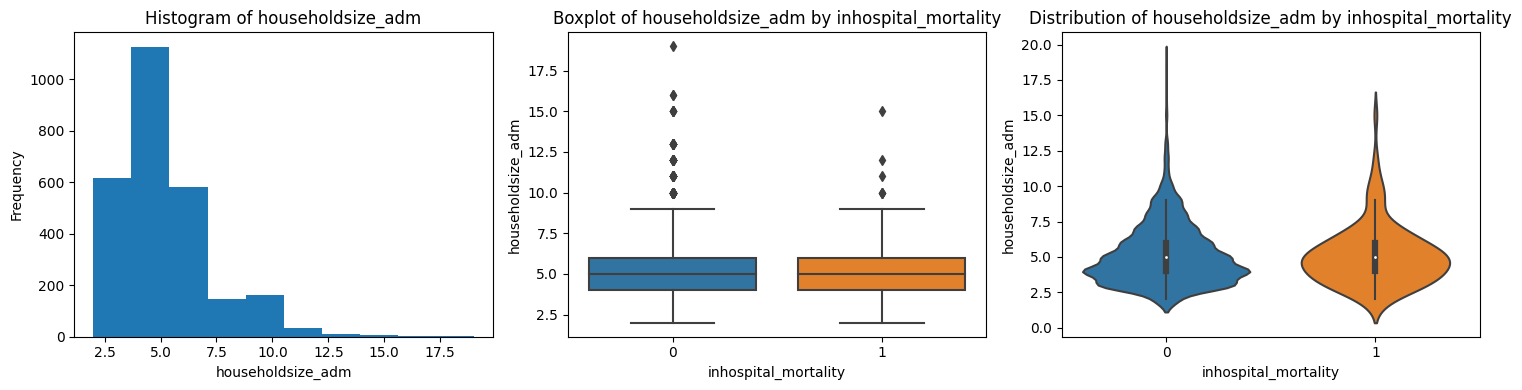

("for 'householdsize_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [107]:
plots_statistical_analysis('householdsize_adm')

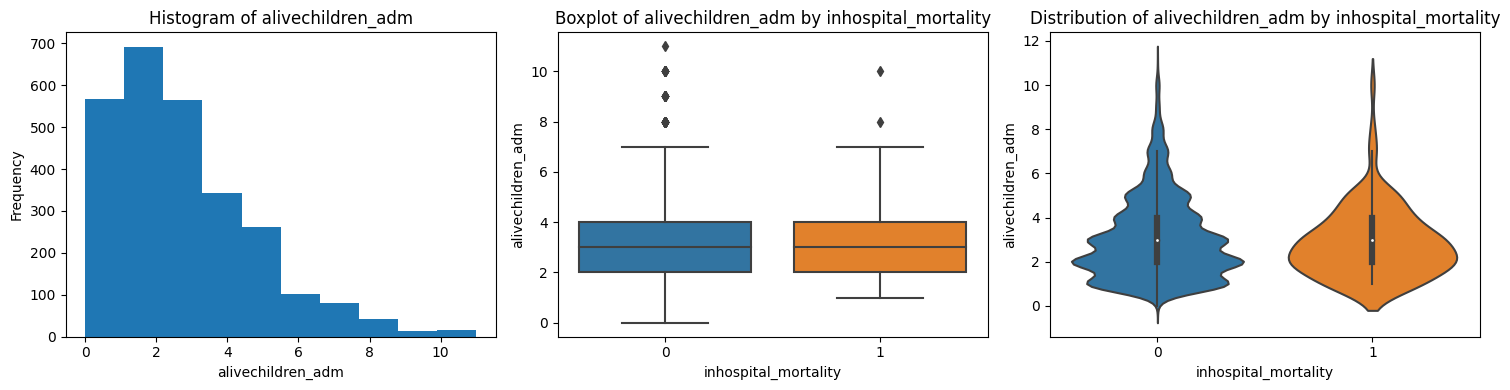

("for 'alivechildren_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [108]:
plots_statistical_analysis('alivechildren_adm')

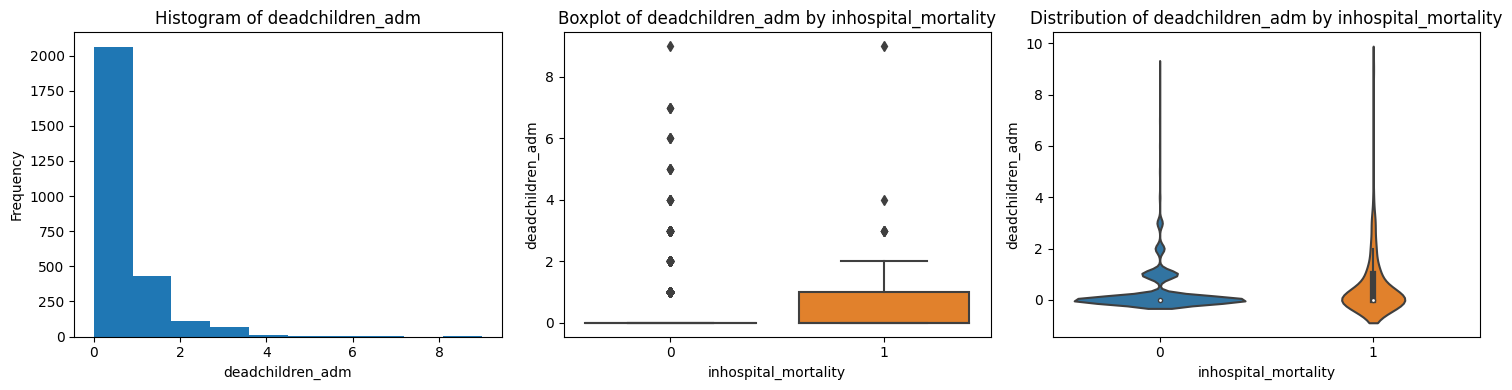

("for 'deadchildren_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [109]:
plots_statistical_analysis('deadchildren_adm')

<Figure size 800x600 with 0 Axes>

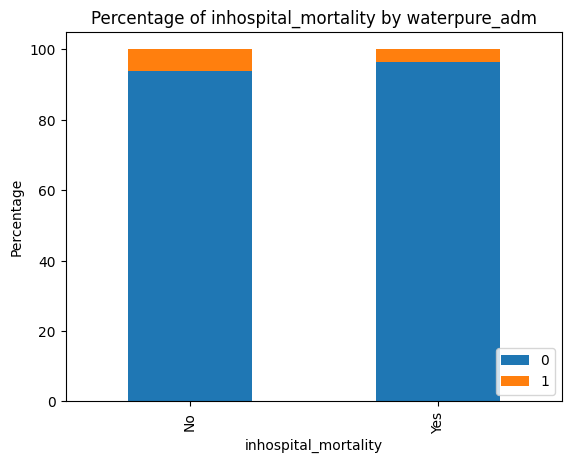

In [110]:
plot_categorical('waterpure_adm')


In [111]:
# Find column headers containing the word 'symptoms'
columns_with_symptoms = [col for col in df.columns if 'cookfuel' in col.lower()]

print(columns_with_symptoms)


['cookfuel_adm___1', 'cookfuel_adm___2', 'cookfuel_adm___3', 'cookfuel_adm___4', 'cookfuel_adm___5', 'cookfuel_adm___6', 'cookfuel_adm___7', 'cookfuel_adm___8']


<Figure size 800x600 with 0 Axes>

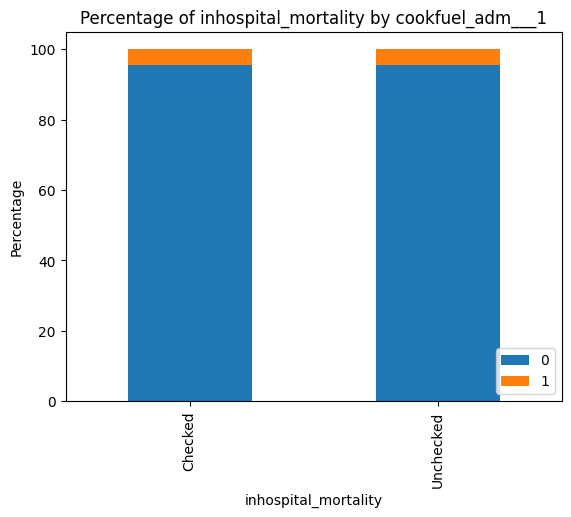

In [112]:
#[Charcoal]
plot_categorical('cookfuel_adm___1')


<Figure size 800x600 with 0 Axes>

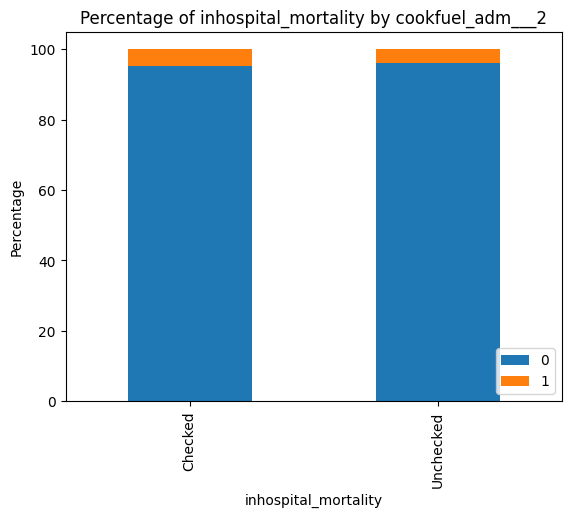

In [113]:
#[Wood]
plot_categorical('cookfuel_adm___2')


<Figure size 800x600 with 0 Axes>

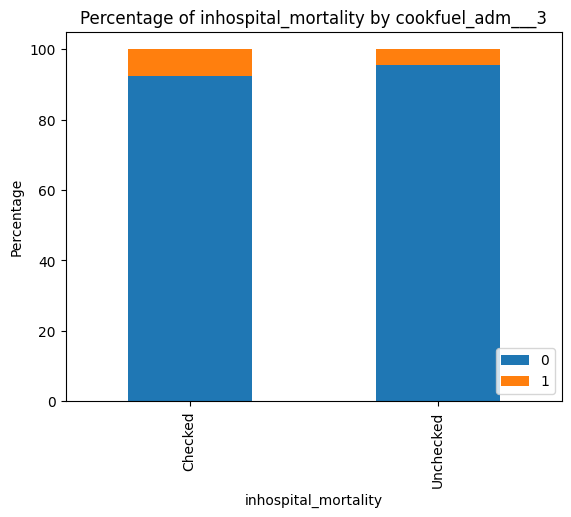

In [114]:
#[Grass/shrubs]
plot_categorical('cookfuel_adm___3')


<Figure size 800x600 with 0 Axes>

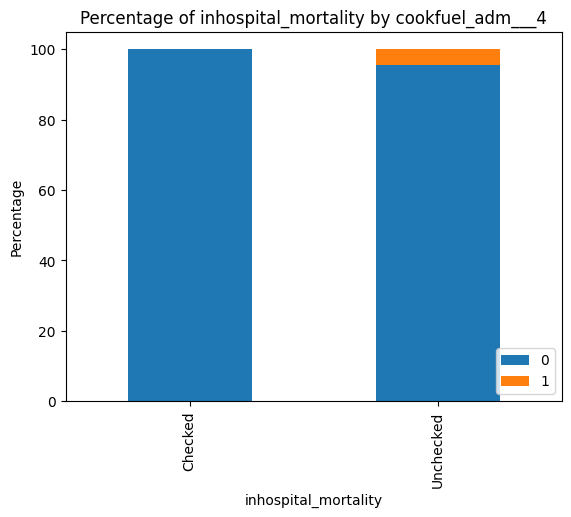

In [115]:
#[Propane]
plot_categorical('cookfuel_adm___4')

<Figure size 800x600 with 0 Axes>

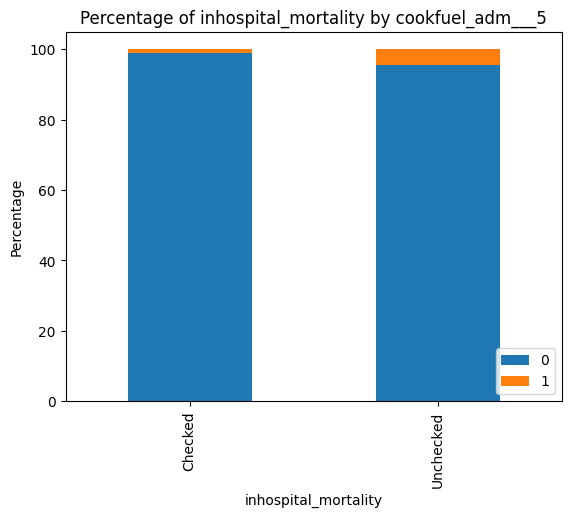

In [116]:
#[Electricity]
plot_categorical('cookfuel_adm___5')

<Figure size 800x600 with 0 Axes>

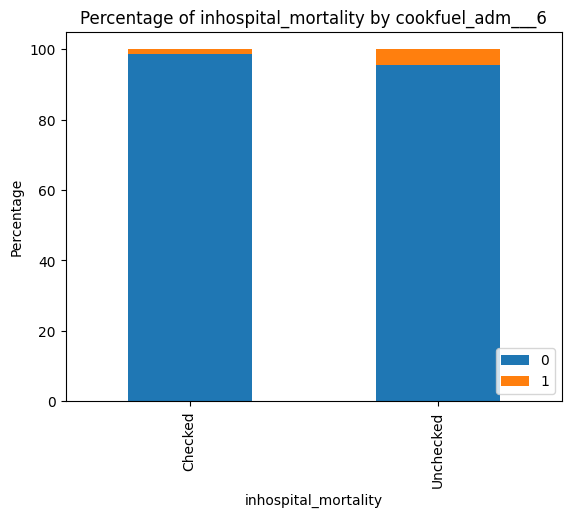

In [117]:
#[Kerosene or Paraffin]
plot_categorical('cookfuel_adm___6')

<Figure size 800x600 with 0 Axes>

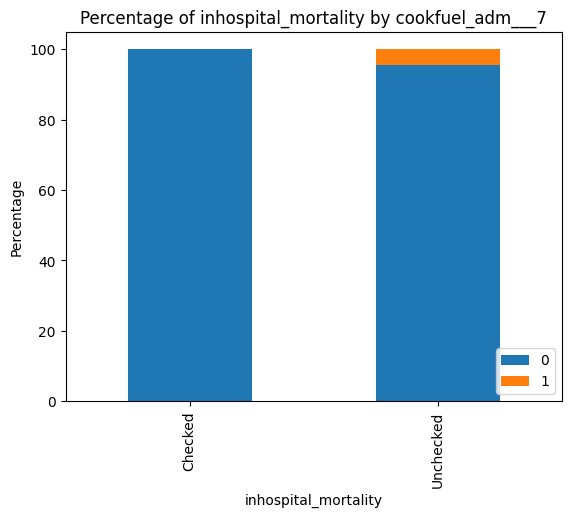

In [118]:
#[Biogas]

plot_categorical('cookfuel_adm___7')

<Figure size 800x600 with 0 Axes>

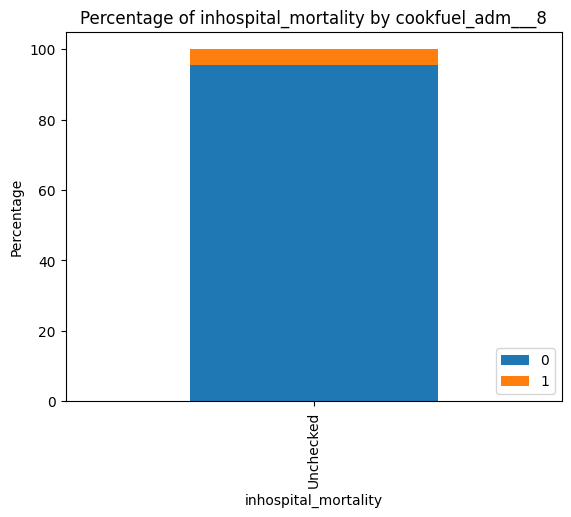

In [120]:
#[Other (specify)]
plot_categorical('cookfuel_adm___8')

<Figure size 800x600 with 0 Axes>

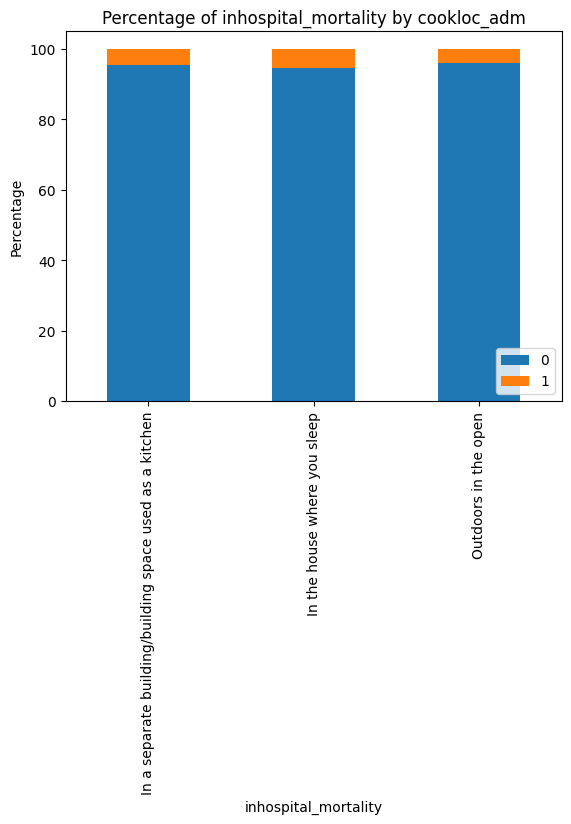

In [122]:
plot_categorical('cookloc_adm')

<Figure size 800x600 with 0 Axes>

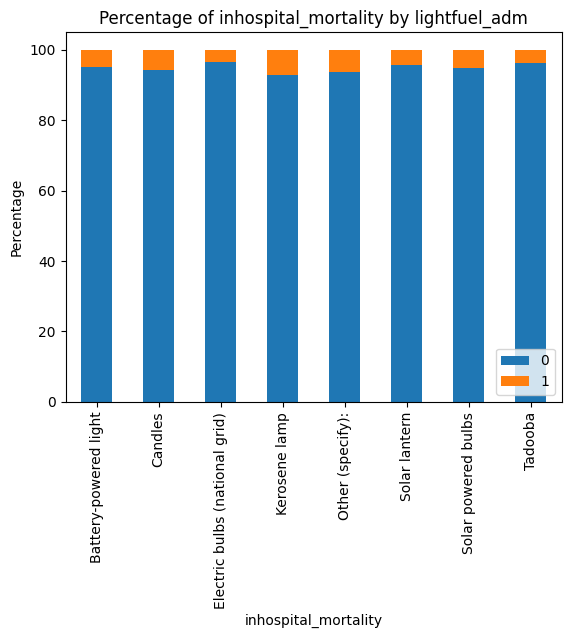

In [124]:
plot_categorical('lightfuel_adm')

<Figure size 800x600 with 0 Axes>

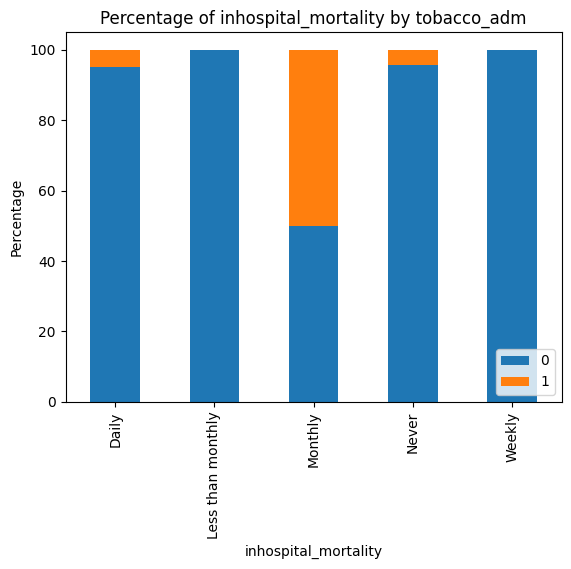

In [126]:
plot_categorical('tobacco_adm')

<Figure size 800x600 with 0 Axes>

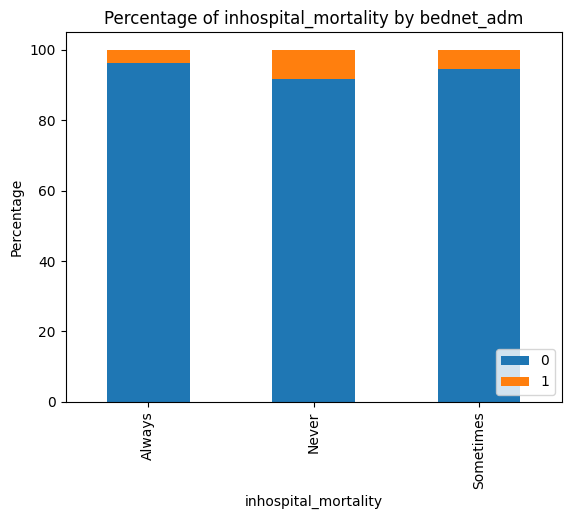

In [128]:
plot_categorical('bednet_adm')

<Figure size 800x600 with 0 Axes>

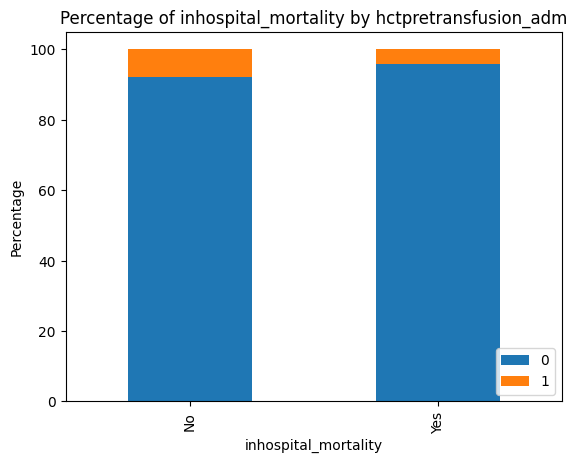

In [130]:
plot_categorical('hctpretransfusion_adm')

<Figure size 800x600 with 0 Axes>

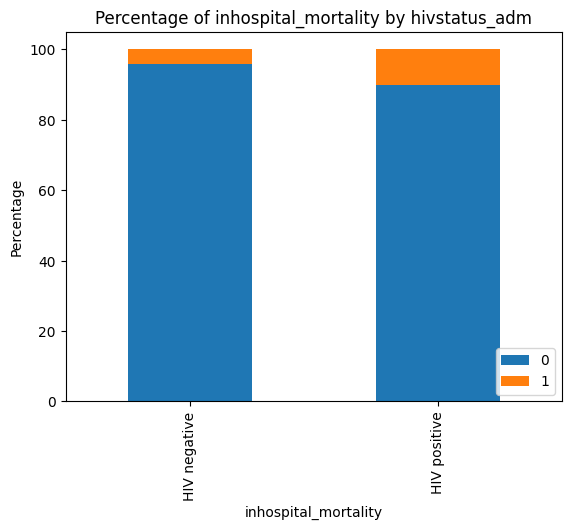

In [132]:
plot_categorical('hivstatus_adm')

<Figure size 800x600 with 0 Axes>

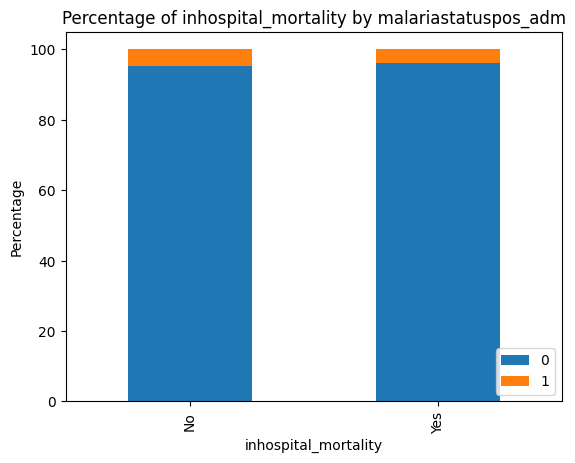

In [134]:
plot_categorical('malariastatuspos_adm')

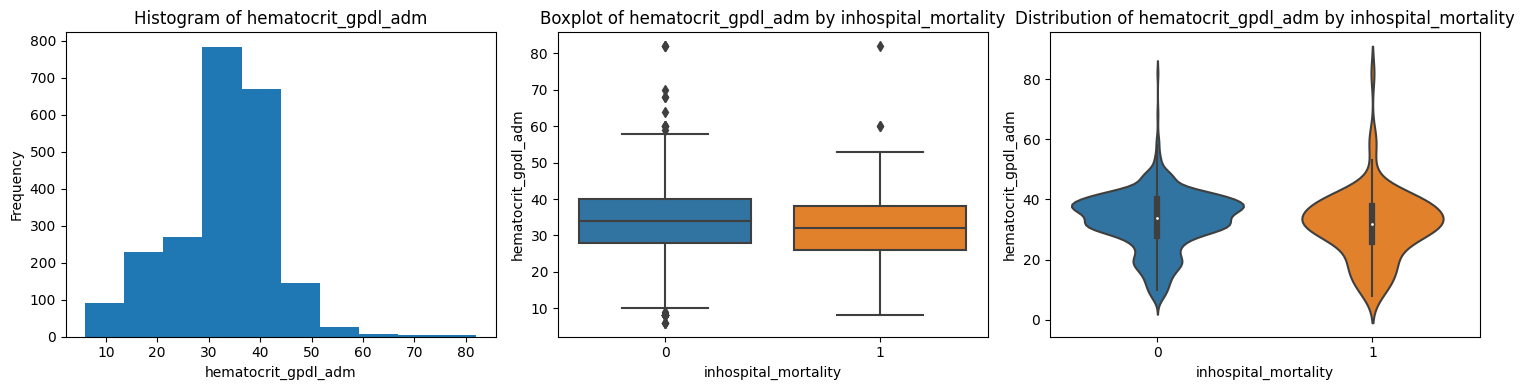

("for 'hematocrit_gpdl_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [136]:
plots_statistical_analysis('hematocrit_gpdl_adm')

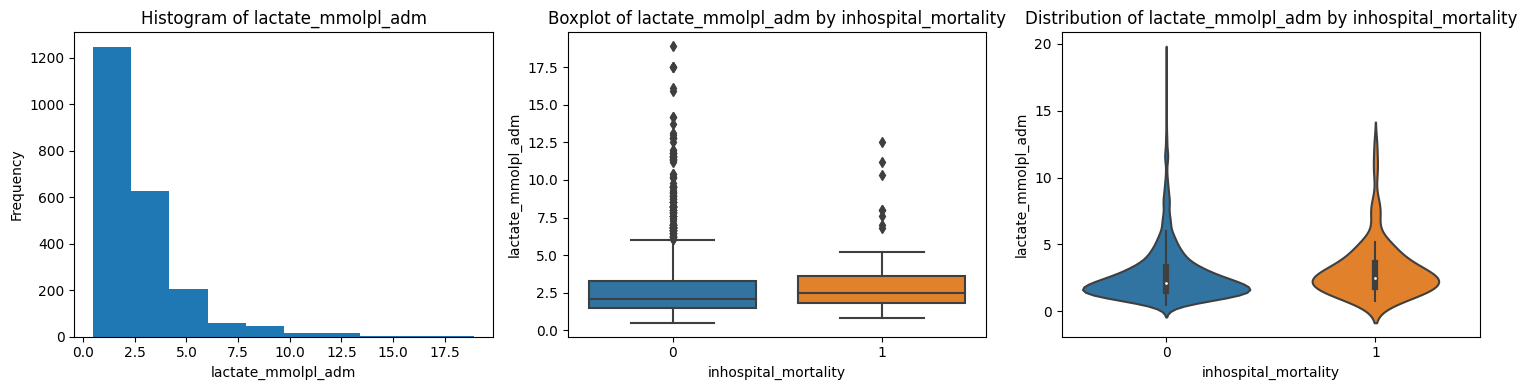

("for 'lactate_mmolpl_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [138]:
plots_statistical_analysis('lactate_mmolpl_adm')

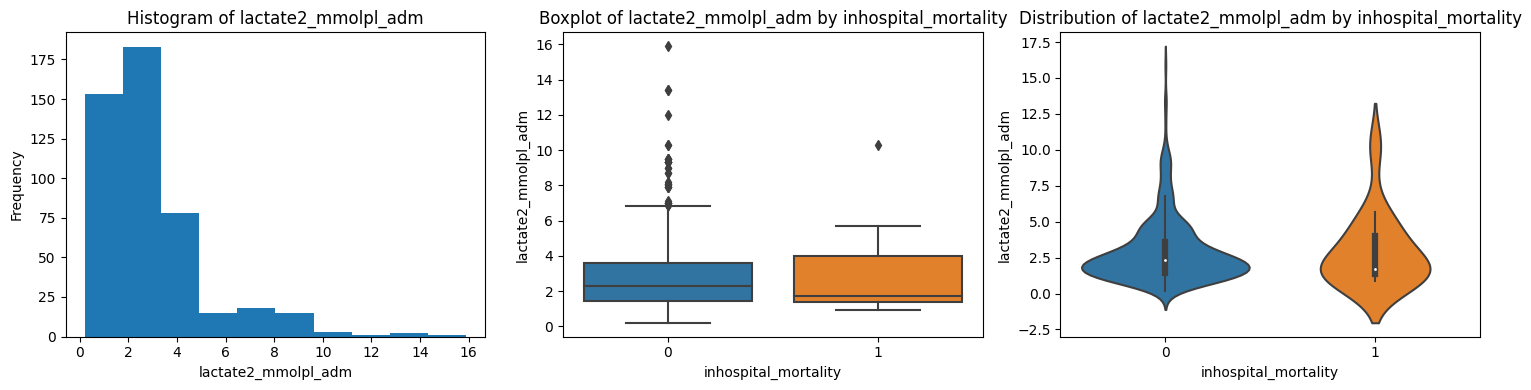

("for 'lactate2_mmolpl_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [140]:
plots_statistical_analysis('lactate2_mmolpl_adm')

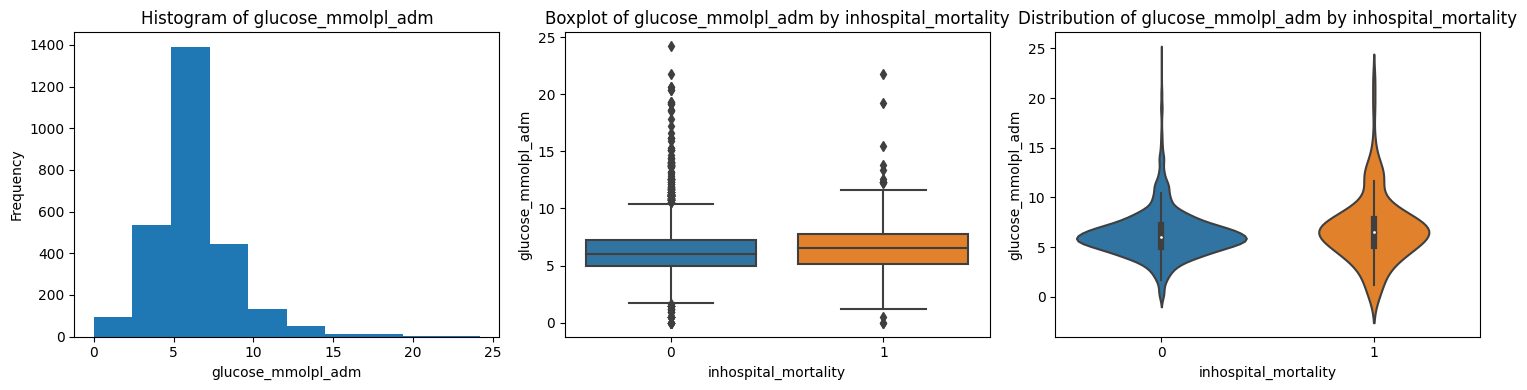

("for 'glucose_mmolpl_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [142]:
plots_statistical_analysis('glucose_mmolpl_adm')

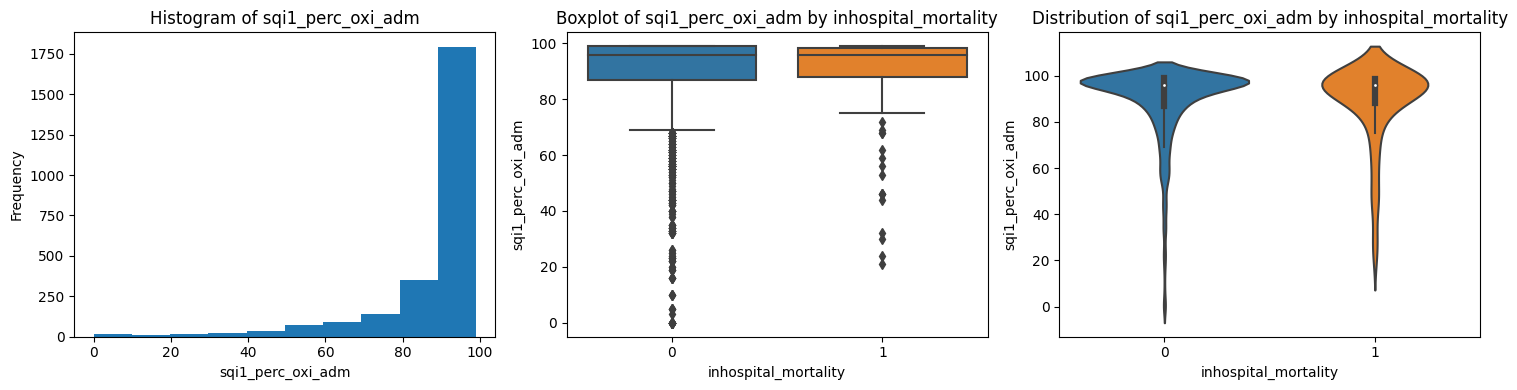

("for 'sqi1_perc_oxi_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [144]:
plots_statistical_analysis('sqi1_perc_oxi_adm')

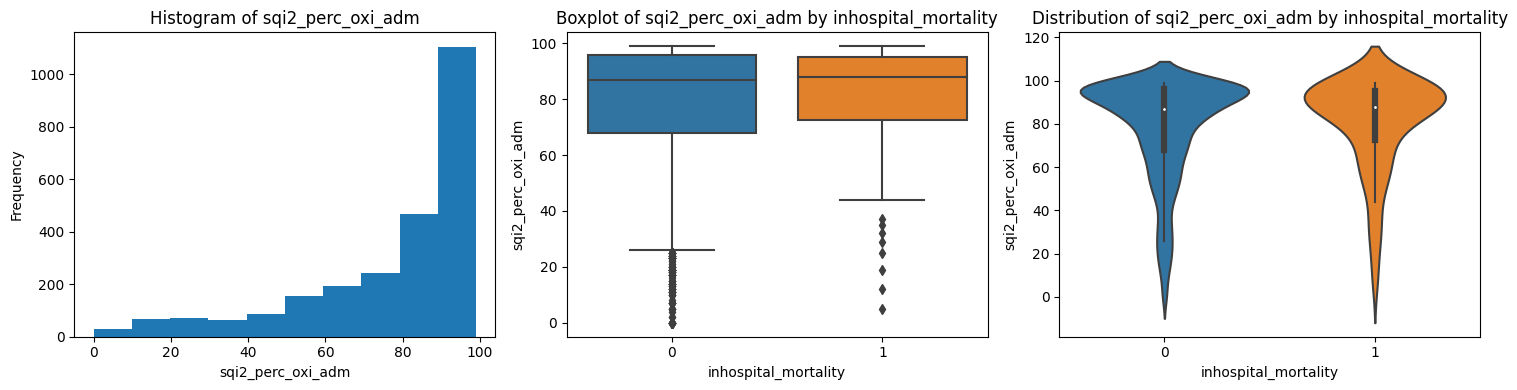

("for 'sqi2_perc_oxi_adm'distirbution is normal",
 ('variance is equal', 'average are equal'))

In [146]:
plots_statistical_analysis('sqi2_perc_oxi_adm')

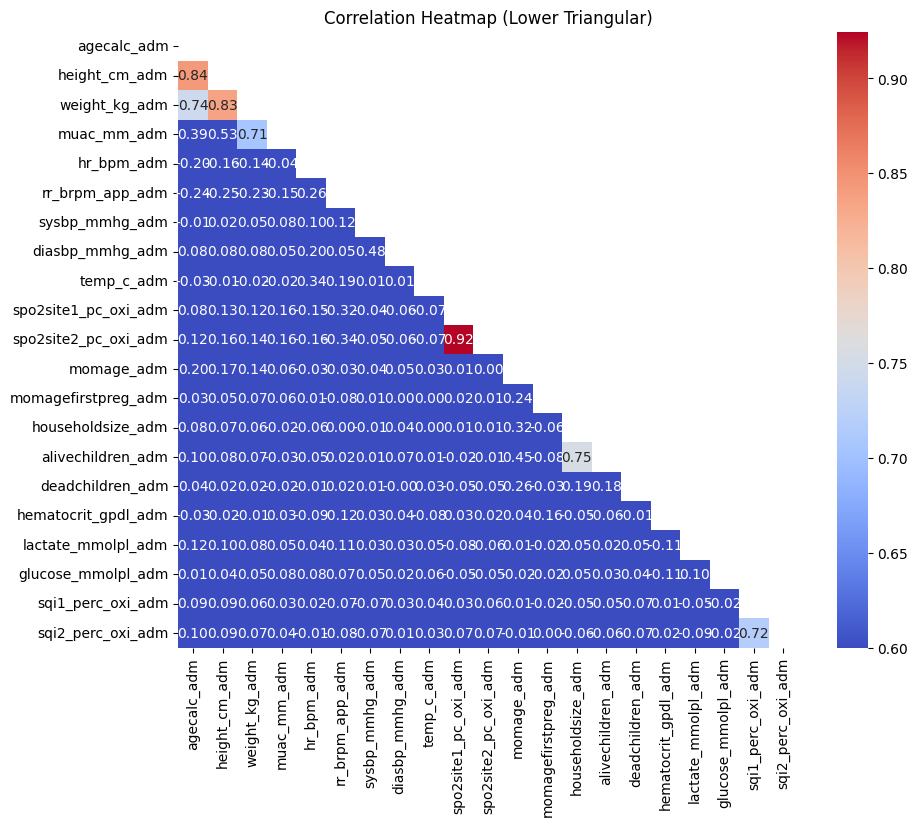

In [150]:
# Select the columns for the heatmap
columns = ['agecalc_adm', 'height_cm_adm', 'weight_kg_adm','muac_mm_adm','hr_bpm_adm','rr_brpm_app_adm','sysbp_mmhg_adm','diasbp_mmhg_adm','temp_c_adm','spo2site1_pc_oxi_adm','spo2site2_pc_oxi_adm','momage_adm','momagefirstpreg_adm','householdsize_adm','alivechildren_adm','deadchildren_adm','hematocrit_gpdl_adm','lactate_mmolpl_adm','glucose_mmolpl_adm','sqi1_perc_oxi_adm','sqi2_perc_oxi_adm']

# Create a subset of the DataFrame with the selected columns
subset = df[columns]

# Calculate the correlation matrix
correlation_matrix = subset.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', mask=mask, vmin=0.6)

# Set the plot title
plt.title('Correlation Heatmap (Lower Triangular)')

# Show the plot
plt.show()

In [155]:

df1 = pd.read_csv('../cleaned_dataset.csv')
df1.head()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,caregiver_adm_new,inhospital_mortality,age_group
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,Mother,0,Toddler (12-23m)
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,Mother,0,Baby (6-11m)
3,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,98.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,Mother,0,Toddler (12-23m)


In [157]:
df1.isnull().sum()

agecalc_adm             0
height_cm_adm           0
weight_kg_adm           0
muac_mm_adm             0
hr_bpm_adm              0
                       ..
hivstatus_adm           0
malariastatuspos_adm    0
caregiver_adm_new       0
inhospital_mortality    0
age_group               0
Length: 112, dtype: int64

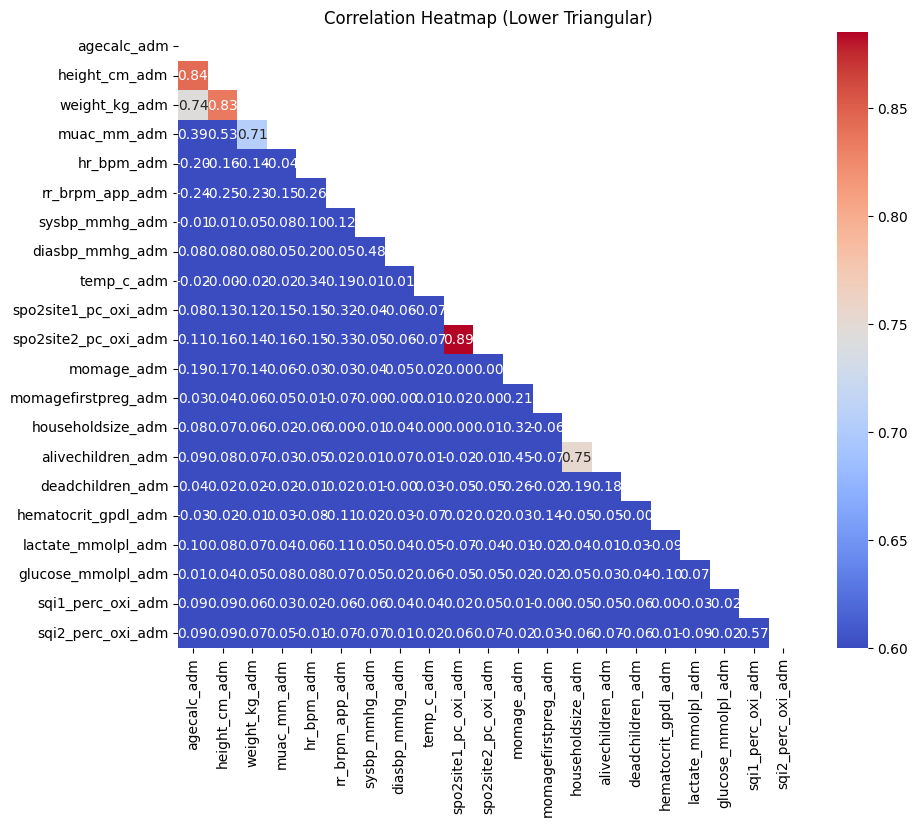

In [159]:
# Select the columns for the heatmap
columns = ['agecalc_adm', 'height_cm_adm', 'weight_kg_adm','muac_mm_adm','hr_bpm_adm','rr_brpm_app_adm','sysbp_mmhg_adm','diasbp_mmhg_adm','temp_c_adm','spo2site1_pc_oxi_adm','spo2site2_pc_oxi_adm','momage_adm','momagefirstpreg_adm','householdsize_adm','alivechildren_adm','deadchildren_adm','hematocrit_gpdl_adm','lactate_mmolpl_adm','glucose_mmolpl_adm','sqi1_perc_oxi_adm','sqi2_perc_oxi_adm']

# Create a subset of the DataFrame with the selected columns
subset = df1[columns]

# Calculate the correlation matrix
correlation_matrix = subset.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', mask=mask, vmin=0.6)

# Set the plot title
plt.title('Correlation Heatmap (Lower Triangular)')

# Show the plot
plt.show()

In [163]:
stat, p = stats.pearsonr(df1['agecalc_adm'], df1['height_cm_adm'])
p

0.0

In [165]:
stat, p = stats.pearsonr(df1['agecalc_adm'], df1['weight_kg_adm'])
p

0.0

In [167]:
stat, p = stats.pearsonr(df1['height_cm_adm'], df1['weight_kg_adm'])
p

0.0

In [169]:
stat, p = stats.pearsonr(df1['height_cm_adm'], df1['muac_mm_adm'])
p

4.3776566818156024e-197

In [173]:
stat, p = stats.pearsonr(df1['spo2site1_pc_oxi_adm'], df1['spo2site2_pc_oxi_adm'])
p

0.0

In [ ]:
The colleration between features above